# **Human Age Prediction: Comparison and Ensembling of Multi-Task, Self-Supervised and Transfer Learning Approaches**

### *Authors*:
- Davide Piatti 

- Simone Pedico 

- Valentyn Piskovskyi 


In this work, we address the human age prediction task by implementing and comparing three complementary approaches.
The final objective was to assess whether it is methodologically sound to incorporate the three developed architectures into an ensemble framework,
with the aim of leveraging the different feature representations the individual networks extract to potentially obtain a model that outperforms each of its individual components.

The learning approches implemented in this work are the following:

- Transfer learning using architectures pre-trained on ImageNet (ResNet152 and EfficientNetB0)  as feature extractors. We chose these models because the residual connections in ResNet152 enable the learning of complex and deep feature representations, while EfficientNetB0 provides a trade-off between performance and computational efficiency.

- Multitasking learning, by leveraging a shared backbone between three different task:
  
  - gender binary classification.
  - face score prediction.
  - age prediction (the real goal).

  The two additional subnetworks are expected to provide a high regularization contribution, which could significantly improve generalization ability of the model. In addition, by learning to predict face visibility scores, the network may learn to ignore certain sources of variation, becoming more robust to noise.

- Self-supervised learning, by implementing an autoencoder with the goal to reconstruct the input images, forcing the encoder to learn informative, possibly age-related, representations without explicit labels. Then, the pre-trained encoder is fine-tuned for age regression.

# Environment Settings

## Import libraries and modules

In [2]:
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras import regularizers
import keras
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import pandas as pd
import numpy as np
import os
from shutil import copyfile
import xml.etree.ElementTree as ET
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Fix seed to ensure reproducibility

In [ ]:
import random as python_random
np.random.seed(0)
python_random.seed(0)
tf.random.set_seed(0)

# Plain Challenge Dataset Import


The dataset we are going to use is publicly available via a GDrive link.
But, it is also available at the following link: https://www.kaggle.com/competitions/age-prediction-spring-25-at-cu-denver/data

The zip folder we are going to download holds the following elements:

- wiki_labeld: the labeled dataset, used to train and test all the models concerning this work. It comprises 60327 100x100 grayscale images of human faces.

- wiki_labele.csv: file containing meta information of each of the 60327 images. Among the others, the main information stored in this file are the following:
  - full_path: directory path, including filename of the image. Its a relative path to the wiki_labeld folder.
  
  - gender: Gender of the subject (0: female, 1: male, NaN if unknown)
  
  - face_score: detector score (the higher the better).
   Inf implies that no face was found in the image, and the face_location then just returns the entire image.
   
  - second_face_score: detector score of the face with the second highest score. This is useful to ignore images with more than one face.
  
  - second_face_score is NaN (not a number) if no second face was detected.
  
  - age: age of the person (in years), and was calculated based on the “dob” value and the “photo_taken” values.
  

The other elements of this zip folder, concerning strictly the challenge itself, are listed below:
  
- wiki_judge: containing 1409 facial images (1.png, etc.) of resolution 100x100. This is the judge/test dataset for the challenge.

- wiki_judge.csv:  contains some meta information described above about the 1409 images. However, the information does not include “age” field.

- sample_submission.csv: a sample submission file in the correct format for the challenge.

In [3]:
# Installing gdown
!pip install -q gdown

# Dataset Gdrive file ID
file_id = '1Frqep7bdhVgvNJfy3Bu7-nQVq-_BYV8L'
output_filename = 'dataset.zip'

# Dowload the dataset only if it is necessary
if not os.path.exists(output_filename):
  # Download the file using gdown
  !gdown --id {file_id} -O {output_filename}

  # Unzipping the downloaded file
  print(f'Successfully downloaded {output_filename}. Unzipping...')
  !unzip -q {output_filename}
  print('Dataset unzipped successfully!')
else:
    print(f'Already downloaded')


/usr/local/lib/python3.12/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1Frqep7bdhVgvNJfy3Bu7-nQVq-_BYV8L
From (redirected): https://drive.google.com/uc?id=1Frqep7bdhVgvNJfy3Bu7-nQVq-_BYV8L&confirm=t&uuid=2ab6d610-c4de-4d06-8695-9d0467fdf33f
To: /content/dataset.zip
100% 332M/332M [00:07<00:00, 45.2MB/s]
Successfully downloaded dataset.zip. Unzipping...
Dataset unzipped successfully!


# Dataset Preprocessing and Analysis


## Dataset Preprocessing

To ensure data quality, we apply the follwing pre-processing pipeline. We decided to select only those images which:

- contain a single face;

- have a face score of at least 4.5;

- have a valid age label (e.g. age between 0 and 110).

In [ ]:
# Reading the dataframe from the 'wiki_labels.csv'
df_labels = pd.read_csv('/content/wiki_labels.csv')
df_labels = df_labels.sort_values(by='full_path', ascending=True)

In [ ]:
# Converting face_score to a numeric type
df_labels['face_score'] = pd.to_numeric(df_labels['face_score'], errors='coerce')

# Selecting only those records that satisfy these constraints:
#
# - valid face_score (i.e. not equal to 'NaN') AND face_score >= 4.5
# - second_face_score equal to 'NaN'
# - valid age (i.e. 0 < age < 110*)
#
# *110 was deliberately chosen as the upper bound for a valid human age.
df_labels = df_labels[df_labels['face_score'].notna() & (df_labels['face_score'] >= 4.5) & (df_labels['second_face_score'].isna()) & ((df_labels['age']>0) & (df_labels['age']<110))]

print(df_labels.head())

          ID     dob          dob_str  photo_taken  \
99      2101  690933  ['16-Sep-1891']         1958   
54573  56575  714492  ['18-Mar-1956']         2007   
700     2702  724857  ['03-Aug-1984']         2009   
50245  52247  723517  ['02-Dec-1980']         2013   
1986    3988  725757  ['20-Jan-1987']         2009   

                                 full_path  gender                       name  \
99     ['00/10049200_1891-09-16_1958.png']     0.0           ['Isabel Jeans']   
54573  ['00/10967900_1956-03-18_2007.png']     0.0  ['Deborah Jeane Palfrey']   
700    ['00/11035100_1984-08-03_2009.png']     1.0          ['Sunil Chhetri']   
50245  ['00/12889900_1980-12-02_2013.png']     0.0       ['Charlotte Rohlin']   
1986   ['00/13016000_1987-01-20_2009.png']     0.0       ['Michelle Maylene']   

                                           face_location  face_score  \
99     [[126.86918793 111.11053944 267.89702434 252.1...    5.254819   
54573  [[ 73.26695603  45.96509752 154.71053

## Dataset Analysis

### Metadata attached to the images

In [ ]:
# Printing out the DataFrame columns
print(df_labels.columns)

Index(['ID', 'dob', 'dob_str', 'photo_taken', 'full_path', 'gender', 'name',
       'face_location', 'face_score', 'second_face_score', 'age'],
      dtype='object')


### Definition of the target labels as Numpy Array

In [ ]:
# Displaying the DF shape to highlight the number of images we would need to load
df_labels.shape

(6663, 11)

In [ ]:
# Due to limited RAM and computational capacity, we restrict our focus on just 3000 images
number_of_train_images = 3000

In [ ]:
# Shuffling the DF records before resizing it
df_labels = df_labels.sample(frac=1, random_state=42).reset_index(drop=True)

In [ ]:
# Age target label
age_labels = df_labels['age'][:number_of_train_images]

# We ceil the 'age' column in order to have smoother target and so a stable learning process.
# Moreover, ceiling this column allow us to augment properly the dataset, as it is later explained.
age_labels = np.array(np.ceil(age_labels), np.float64)

# The two additional target variables for the Multi tasking approach

# 'gender' classification
gender_labels = df_labels['gender'][:number_of_train_images]
gender_labels = np.array(gender_labels, np.int8)

# 'face_score' prediction
face_score_labels = df_labels['face_score'][:number_of_train_images]
face_score_labels = np.array(face_score_labels, np.float64)

/usr/local/lib/python3.12/dist-packages/pandas/core/series.py:1031: RuntimeWarning: invalid value encountered in cast
  arr = np.asarray(values, dtype=dtype)


### Age distribution

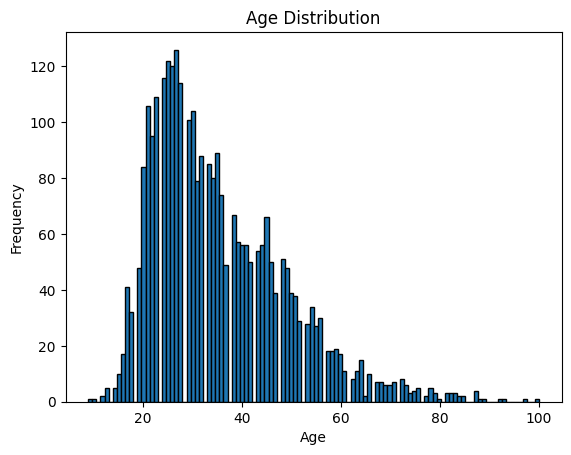

In [ ]:
plt.hist(age_labels, bins=110, edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')
plt.show()

### Face score distribution

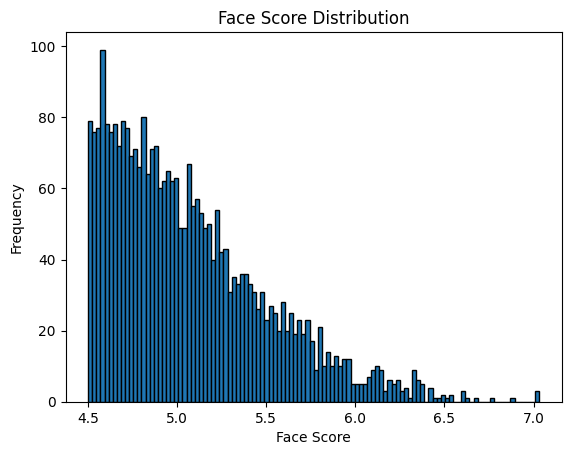

In [ ]:
plt.hist(face_score_labels, bins=110, edgecolor='black')
plt.xlabel('Face Score')
plt.ylabel('Frequency')
plt.title('Face Score Distribution')
plt.show()

### Gender distribution

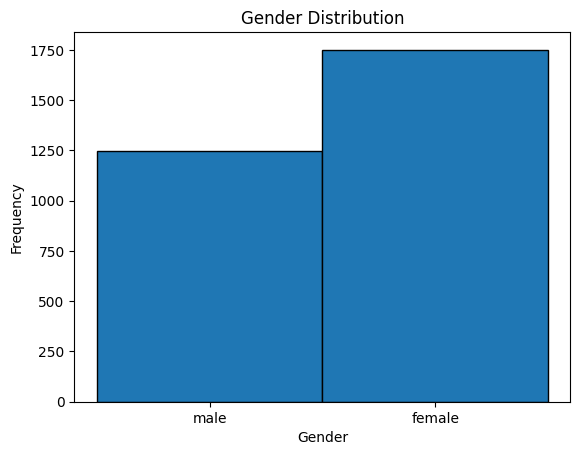

In [ ]:
# Just to put the labels 'male' and 'female' at the center of the respective bins.
bins = [-0.5, 0.5, 1.5]

plt.hist(gender_labels, bins=bins, edgecolor='black')
plt.xticks([0, 1], ['male', 'female'])
plt.xlabel('Gender')
plt.ylabel('Frequency')
plt.title('Gender Distribution')

plt.show()

## Images Loading

In [ ]:
# Loading the paths to all images referenced by the DF so far treated
images_paths = df_labels['full_path'][:number_of_train_images]
images_paths = np.array(images_paths)

In [ ]:
# Displaying the paths
images_paths

array(["['03/620803_1976-04-16_2007.png']",
       "['72/13115172_1921-09-26_2008.png']",
       "['95/2452095_1953-06-16_2013.png']", ...,
       "['62/14990262_1984-06-23_2010.png']",
       "['34/28355734_1984-10-28_2015.png']",
       "['73/26531073_1991-05-23_2010.png']"], dtype=object)

**Loading images from disk**

In [ ]:
# Where the images folders reside
base_folder = 'wiki_labeled/wiki_labeled/'

# List of the loaded images.
# Initially empty and incrementally updated in the following loop
images = []

for filename in images_paths:

    # Removing invalid character from the current filename
    filename = filename.strip('[\' ] ')

    # Reading the grayscale image referenced by the current filename
    img = keras.utils.load_img(path = base_folder+filename,color_mode="grayscale", target_size=(100,100))

    # Turning images into array
    img = keras.utils.img_to_array(img)

    # Further control over current read image
    if img is not None:
      images.append(img)

# Turning the image list into a Numpy array
images = np.array(images, np.uint8)

In [ ]:
# Checking the shape of the numpy array of images
print(images.shape)

(3000, 100, 100, 1)


**Images Visualization**

2732
['21/16021_1942-03-02_2010.png']


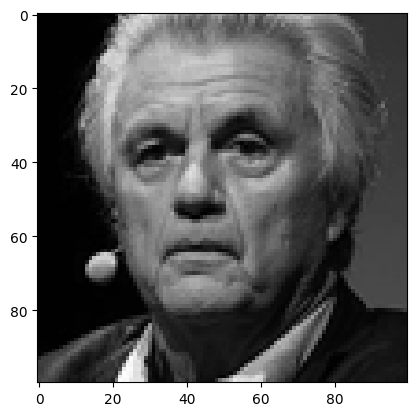

Label equal to:  {np.float64(68.0)}


In [ ]:
# Random index that span the array of images
random_index = np.random.randint(0, len(images)-1)
print(random_index)

# Plotting the current sampled image
plt.imshow(images[random_index],cmap='gray')
print(images_paths[random_index])
plt.show()

# Printing out the age label corresponding to the current sampled image
print(f"Label equal to: ", {age_labels[random_index]})

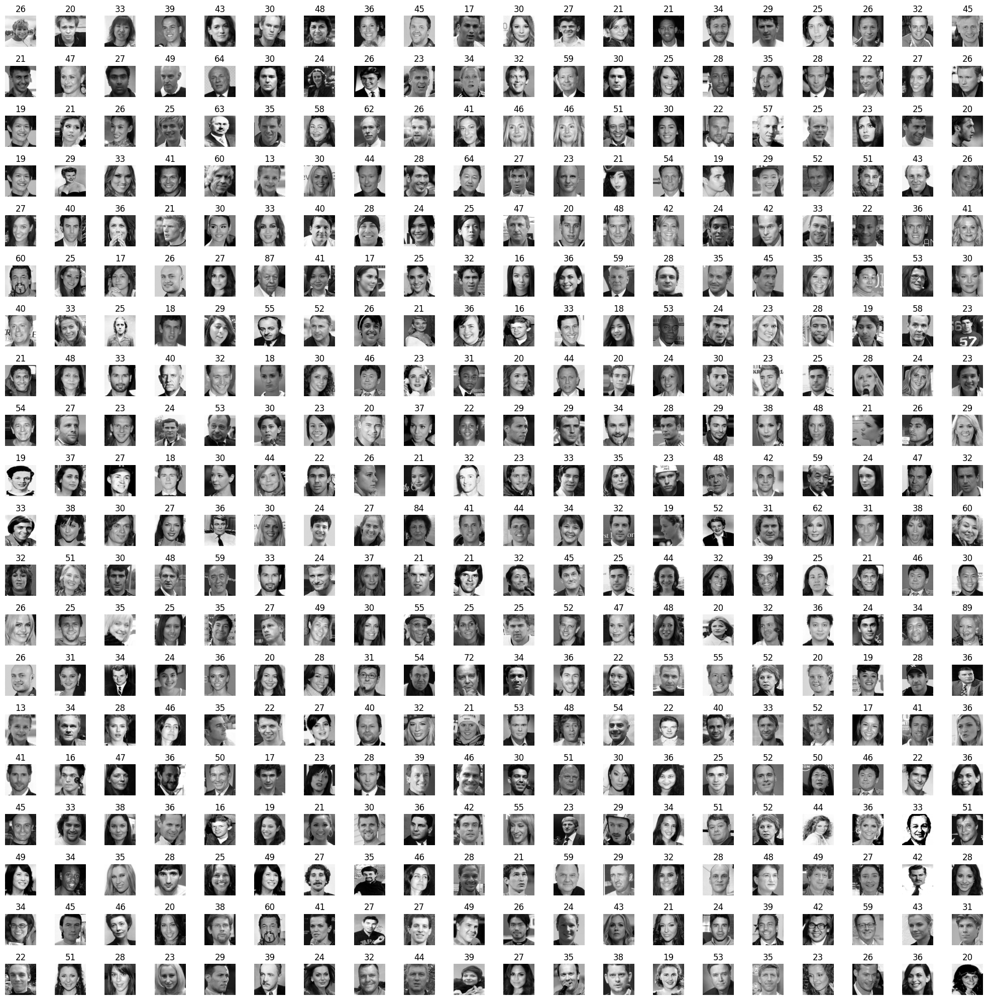

In [ ]:
# Plotting some of the images and their age labels
fig, axes = plt.subplots(20, 20, figsize=(20, 20))
for i, ax in enumerate(axes.flat):
    if i < len(images):
        random_index = np.random.randint(0, len(images) - 1)
        ax.imshow(images[random_index],cmap='gray')
        ax.set_title(f'{age_labels[random_index]:.0f}')
        ax.axis('off')
plt.tight_layout()

# Saving the plot to disk
plt.savefig('age_grid_plot.png')
plt.show()

## Train set and Test set Definition

In order to get some preliminary insight about the quality of the models we are going to implement, we split our current dataset in Train e Test sets. Since the judgement set lacks of age labels, this seemed to be the right thing to do in order to assess our models.

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test, train_gender, test_gender, train_face_score, test_face_score = train_test_split(images, age_labels, gender_labels, face_score_labels, test_size=0.3, random_state=42)

In [ ]:
# Assuring that train_test_split returned Numpy arrays

print(type(X_train))
print(type(X_test))
print(type(y_train))
print(type(y_test))
print(type(train_gender))
print(type(test_gender))
print(type(train_face_score))
print(type(test_face_score))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [ ]:
# Checking the dtype of each of the Numpy arrays returned by train_test_split

print(X_train.dtype)
print(X_test.dtype)
print(y_train.dtype)
print(y_test.dtype)
print(train_gender.dtype)
print(test_gender.dtype)
print(train_face_score.dtype)
print(test_face_score.dtype)

uint8
uint8
float64
float64
int8
int8
float64
float64


In [ ]:
# Checking the shape of each of the Numpy arrays returned by train_test_split

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)
print(train_gender.shape)
print(test_gender.shape)
print(train_face_score.shape)
print(test_face_score.shape)

(2100, 100, 100, 1)
(900, 100, 100, 1)
(2100,)
(900,)
(2100,)
(900,)
(2100,)
(900,)


## Data augmentation

We apply a training set augmentation, aiming at balacing the age distribution.

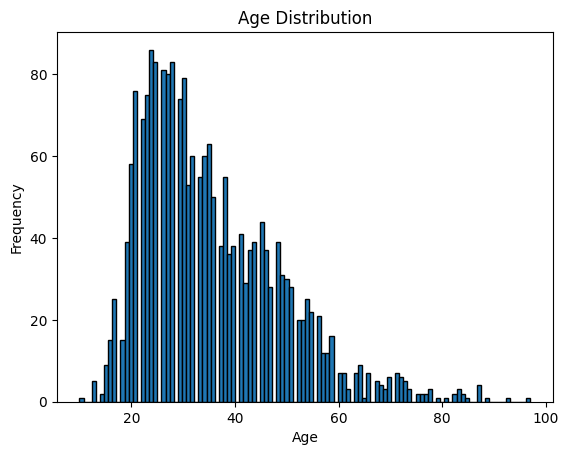

In [ ]:
# Plotting the age distribution in the training set

plt.hist(y_train, bins=110, edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')
plt.show()

In [ ]:
from scipy.stats import mode

age_mode = mode(np.ceil(y_train))
print(f"Mode of age labels: {age_mode.mode}")

Mode of age labels: 24.0


In [ ]:
print(f"Frequency of mode: {age_mode.count}")

Frequency of mode: 86


For each age not equal to the mode, we calculate how many images should be included in the training set, in order to balance the overall age distribution.

In [ ]:
# List of the all the images indeces to which we will apply the augmentation
indices_to_augment = []

for age in range(1, 111):

    # Indeces of all the images whose labels are equal to [age]
    indices_for_age = np.where(np.ceil(y_train) == age)[0]

    # If [age] is represented in the training set
    if (indices_for_age.shape[0] != 0):

      # How many sample of [age] does the training set is currently missing, w.r.t. to the age mode?
      q = int(age_mode.count / indices_for_age.shape[0])
      r = age_mode.count % indices_for_age.shape[0]
      #print("age: ", age, ", indces: ", indices_for_age.shape[0], ", q: ", q, ", r: ", r)

      # Extending [q-1] times the global list [indices_to_augment] with the indeces included in [indices_for_age].
      # "q-1" is necessary since the training set natively comprises a first "instance" of the images bounded to the indeces included in [indices_for_age].
      for _ in range(q-1):
          indices_to_augment.extend(indices_for_age)

      # Filling the remainig gap between the target age mode distribution and the current age distribution
      # With random indeces sampled from [indices_for_age]
      for _ in range(r):
          indices_to_augment.append(indices_for_age[np.random.randint(0, indices_for_age.shape[0])])

# Numpy array of indeces of the images to which augmentation will be applied
indices_to_augment = np.array(indices_to_augment)

print(f"Total sampled indices: {len(indices_to_augment)}")
print(f"Example sampled indices: {indices_to_augment[:10]}")

Total sampled indices: 4522
Example sampled indices: [1004 1004 1004 1004 1004 1004 1004 1004 1004 1004]


### Image Transformations
The transformation that give rise to the data augmentation

In [ ]:
augmentation_layers = [

    # Random crop
    keras.layers.RandomCrop(70, 70),

    # Resizing in order to meet again the original dataset image specification
    keras.layers.Resizing(100, 100),

    # Horizontal random flip and random rotation
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.5),

    # Brightness and contrast random adjusment, whose parameters aim to highlight the facial traits
    keras.layers.RandomBrightness((-0.3,0.2)), # decreasing brightness
    keras.layers.RandomContrast((0.2,0.4)), # enhacing contrast
]

def data_augmentation(x, y=None, y2=None, y3=None):
    # Cast to float32 as Keras layers expect float inputs
    x = tf.cast(x, tf.float32)
    for layer in augmentation_layers:
          x = layer(x)
    return x, y, y2, y3

### Visualizing the transformation effects

In [ ]:
# Small TensorFlow Dataset sample to which apply the data augmentation transformation
ds_temp = tf.data.Dataset.from_tensors(X_train[:25])

# Applyng the transformations
augmented_ds_temp = ds_temp.map(data_augmentation, num_parallel_calls=tf.data.AUTOTUNE)

# list of images reflecting the effect of the transformation applied before
augmented_images_temp = []

# Retriving the transformed images from the TensorFlow dataset
for img_batch, _, _, _ in augmented_ds_temp.batch(32):
    augmented_images_temp.append(img_batch.numpy().astype("uint8"))

# Numpy array of transformed images
augmented_images_temp = np.array(augmented_images_temp[0][0])

# Checking type and shape of the original and corresponding set of transformed images
print(type(augmented_images_temp))
print(type(X_train[:25]))

print(augmented_images_temp.shape)
print(X_train[:25].shape)

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
(25, 100, 100, 1)
(25, 100, 100, 1)


**Original images visualization**

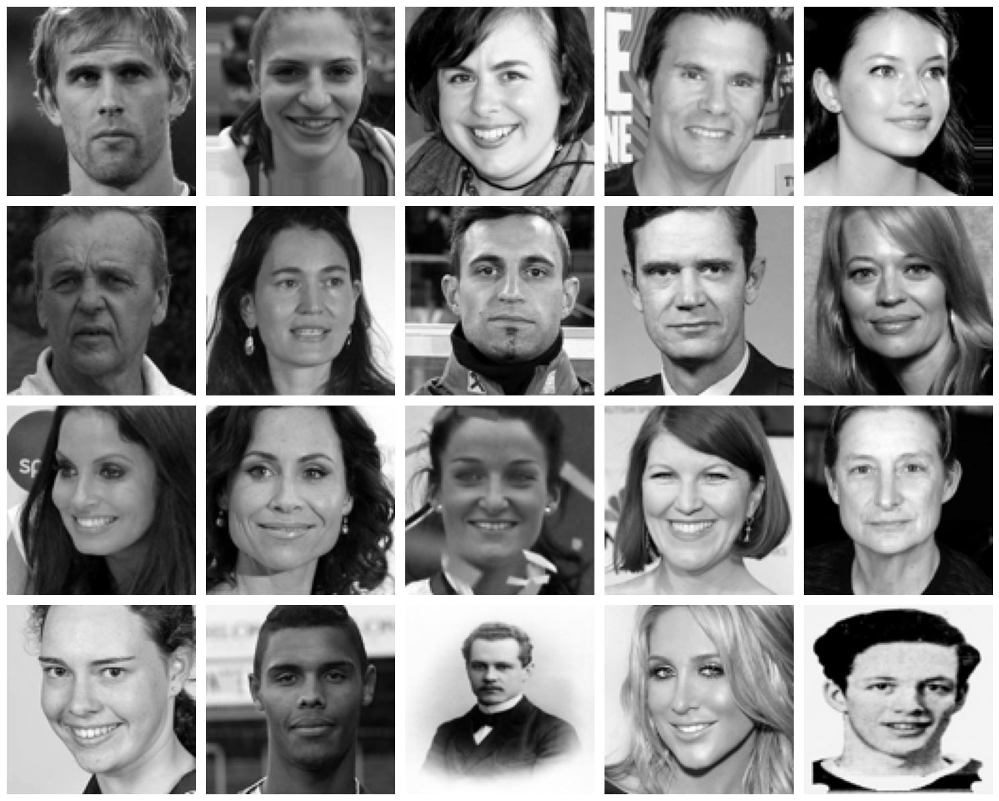

In [ ]:
plt.figure(figsize=(15, 15))
for i in range(20):
    ax = plt.subplot(5, 5, i + 1)
    img_to_show = X_train[i]
    plt.imshow(img_to_show.astype("uint8"), cmap="gray")
    plt.axis("off")
plt.tight_layout()
plt.show()

**Corresponding tranformed images visualization**

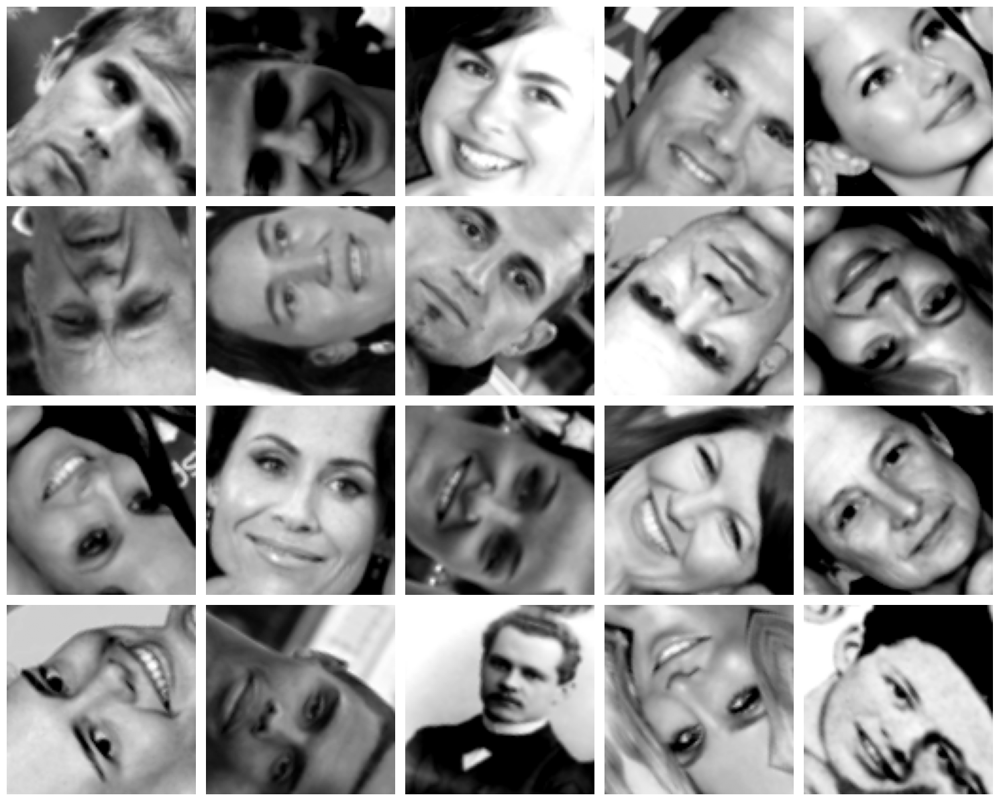

In [ ]:
# after augmentation
plt.figure(figsize=(15, 15))
for i in range(20):
    ax = plt.subplot(5, 5, i + 1)
    img_to_show = augmented_images_temp[i]
    plt.imshow(img_to_show.astype("uint8"), cmap="gray")
    plt.axis("off")
plt.tight_layout()
plt.show()

### Applying data augmentation to the training set

In [ ]:
# Extracting the subset of X_train and y_train corresponding to the image-to-augment indices
subset_X_to_augment = X_train[indices_to_augment]
subset_y_to_augment = y_train[indices_to_augment]
subset_y2_to_augment = train_gender[indices_to_augment]
subset_y3_to_augment = train_face_score[indices_to_augment]


# Converting this subset to tf.data.Dataset to easily apply the data_augmentation function
subset_tf_dataset_for_aug = tf.data.Dataset.from_tensor_slices((subset_X_to_augment, subset_y_to_augment, subset_y2_to_augment,subset_y3_to_augment))


# Applyng the data_augmentation function to the subset
augmented_subset_tf_dataset = subset_tf_dataset_for_aug.map(data_augmentation, num_parallel_calls=tf.data.AUTOTUNE)


# Converting the augmented tf.data.Dataset subset back to NumPy arrays
newly_augmented_images_list = []
newly_augmented_labels_list = []
newly_augmented_labels2_list = []
newly_augmented_labels3_list = []


# Iterating over the batched dataset and converting each element to a NumPy array
for img_batch, label_batch, label2_batch, label3_batch in augmented_subset_tf_dataset.batch(32):
    newly_augmented_images_list.append(img_batch.numpy().astype("uint8"))
    newly_augmented_labels_list.append(label_batch.numpy())
    newly_augmented_labels2_list.append(label2_batch.numpy())
    newly_augmented_labels3_list.append(label3_batch.numpy())

newly_augmented_images = np.concatenate(newly_augmented_images_list, axis=0)
newly_augmented_labels = np.concatenate(newly_augmented_labels_list, axis=0)
newly_augmented_labels2 = np.concatenate(newly_augmented_labels2_list, axis=0)
newly_augmented_labels3 = np.concatenate(newly_augmented_labels3_list, axis=0)


# Concatenating the newly augmented data to the existing X_train and y_train counterparts
X_train_aug = np.concatenate([X_train, newly_augmented_images], axis=0)
y_train_aug = np.concatenate([y_train, newly_augmented_labels], axis=0)
train_gender_aug = np.concatenate([train_gender, newly_augmented_labels2], axis=0)
train_face_score_aug = np.concatenate([train_face_score, newly_augmented_labels3], axis=0)

**Checking the shape and types of the new X_train and y_train labels**

In [ ]:
print(type(X_train_aug))
print(type(y_train_aug))
print(type(train_gender_aug))
print(type(train_face_score_aug))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


In [ ]:
print(X_train_aug.dtype)
print(y_train_aug.dtype)
print(train_gender_aug.dtype)
print(train_face_score_aug.dtype)

uint8
float64
int8
float64


In [ ]:
print(X_train_aug.shape)
print(y_train_aug.shape)
print(train_gender_aug.shape)
print(train_face_score_aug.shape)

(6622, 100, 100, 1)
(6622,)
(6622,)
(6622,)


**Shuffling the augmented training set**


Since augmented images where concatenated to the origianl Numpy arrays.

In [ ]:
shuffled_indices = np.random.permutation(len(X_train_aug))

X_train_aug = X_train_aug[shuffled_indices]
y_train_aug = y_train_aug[shuffled_indices]
train_gender_aug = train_gender_aug[shuffled_indices]
train_face_score_aug = train_face_score_aug[shuffled_indices]

### Distribution of Age after augmentation

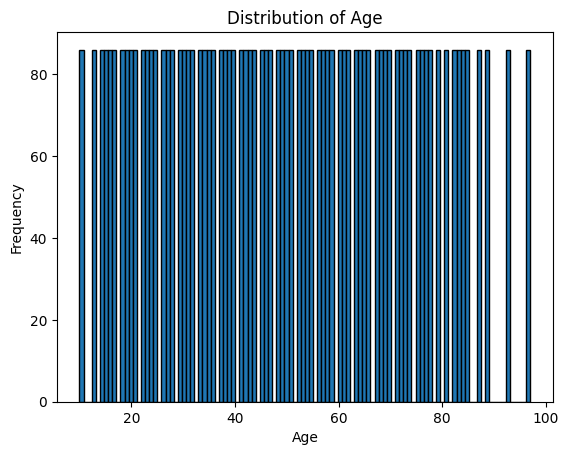

In [ ]:
plt.hist(y_train_aug, bins=110, edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Distribution of Age')
plt.show()

In [ ]:
np.mean(y_train_aug)

np.float64(50.298701298701296)

In [ ]:
np.std(y_train_aug)

np.float64(22.828021590622924)

#### Distribution of Face score after augmentation

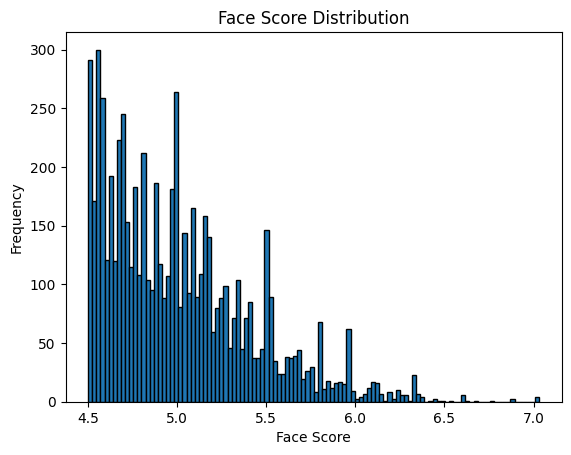

In [ ]:
plt.hist(train_face_score_aug, bins=110, edgecolor='black')
plt.xlabel('Face Score')
plt.ylabel('Frequency')
plt.title('Face Score Distribution')
plt.show()

### Distribution of Gender after augmentation

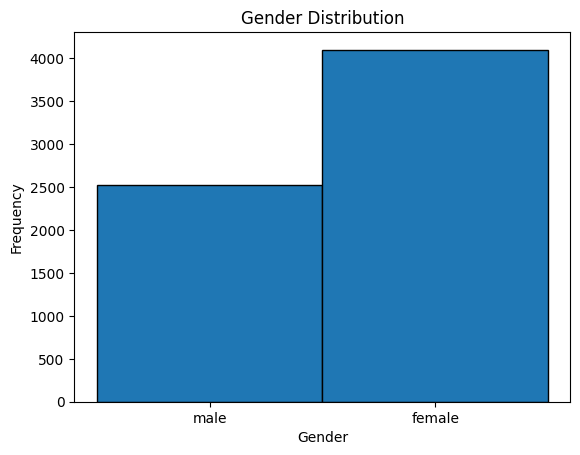

In [ ]:
# Just to put the labels 'male' and 'female' at the center of the respective bins.
bins = [-0.5, 0.5, 1.5]

plt.hist(train_gender_aug, bins=bins, edgecolor='black')
plt.xticks([0, 1], ['male', 'female'])
plt.xlabel('Gender')
plt.ylabel('Frequency')
plt.title('Gender Distribution')

plt.show()

### Augmented Training Set Images Visualization

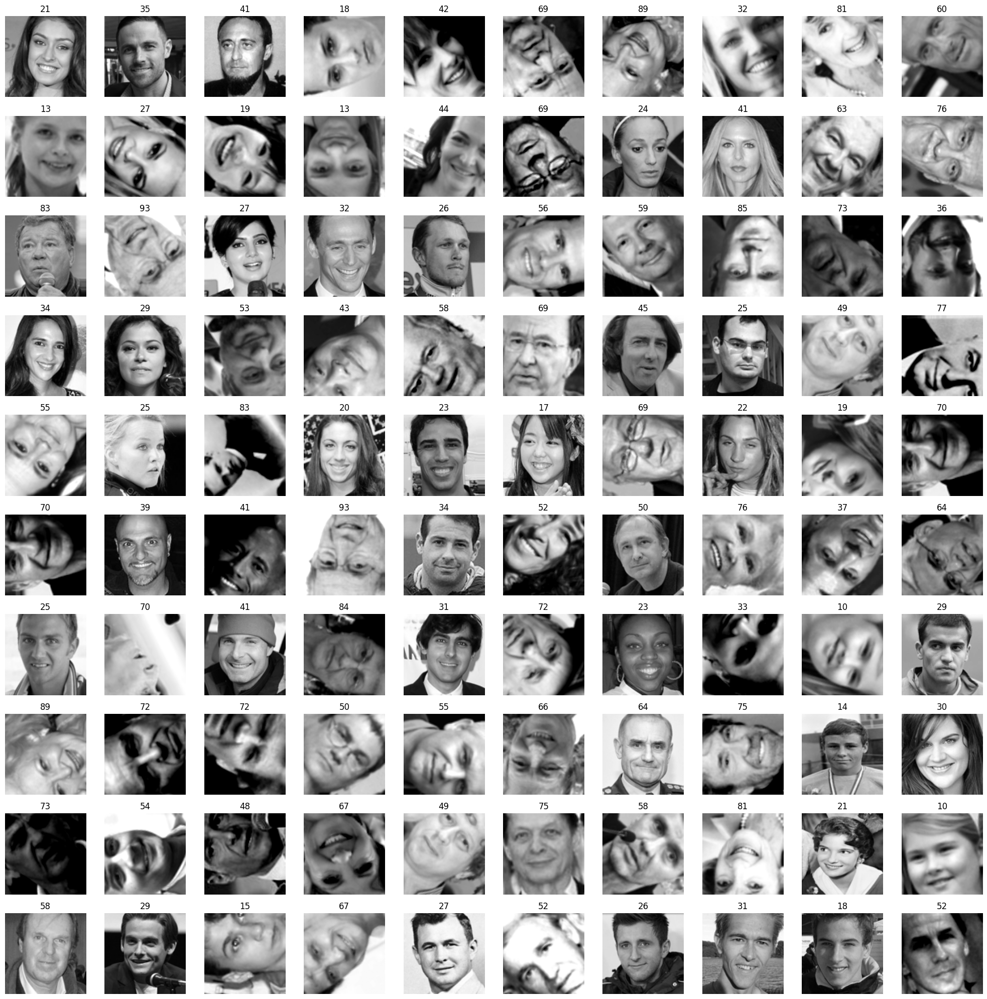

In [ ]:
fig, axes = plt.subplots(10, 10, figsize=(20, 20))
for i, ax in enumerate(axes.flat):
    random_index = np.random.randint(0, len(X_train_aug) - 1)
    ax.imshow(X_train_aug[random_index], cmap="gray")
    ax.set_title(f'{y_train_aug[random_index]:.0f}') # Display age label, formatted as integer
    ax.axis('off')
plt.tight_layout()

# Save the plot to disk before displaying it
plt.savefig('age_grid_plot.png')
plt.show()

## Min-Max Age Scaling

In [ ]:
# Min-Max scaling parameters
age_min = y_train_aug.min()
age_max = y_train_aug.max()

# Min-Max scaling functions
def minmax_scale(y, min_val, max_val):
    return (y - min_val) / (max_val - min_val)

def minmax_unscale(y_norm, min_val, max_val):
    return y_norm * (max_val - min_val) + min_val

# Min-Max age scaling on the training set
y_train_norm = minmax_scale(y_train_aug, age_min, age_max)

# Transfer learning Approach

## EfficientNet

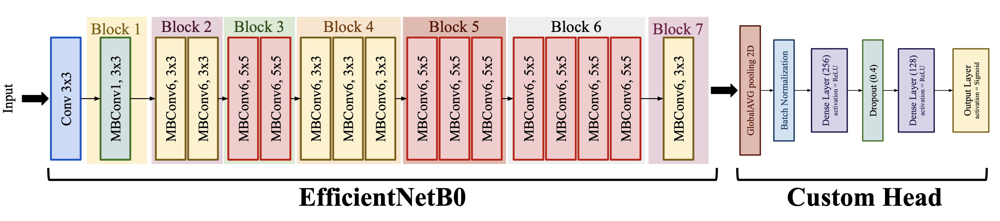

### Model Definition

In [ ]:
# Loading the EfficientNetB0 architecture pre-trained on ImageNet
base_net = keras.applications.EfficientNetB0(
    input_shape=(224,224,3),
    weights="imagenet",
    include_top=False,
    pooling=None # keeps the spatial feature maps as output (allowing manual definition of a custom pooling layer in the new head)
)
base_net.trainable = False  # freezing all layers of the backbone.

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


**Custom  head**

In [ ]:
# Defining the model input, grayscale images of size 100x100 (1 channel)
Inputs = keras.Input((100, 100, 1))

# Resizing images from 100x100 to 224x224 to match EfficientNetB0 expected input size
x = layers.Resizing(224, 224)(Inputs)

# Since EfficientNet was trained on 3-channel ImageNet images, I convert grayscale images (1 channel) to RGB (3 channels)
x = layers.Lambda(lambda x: tf.image.grayscale_to_rgb(x))(x)

# Apply efficientNet preprocessing
x = keras.applications.efficientnet.preprocess_input(x)

# Passing the preprocessed input through the frozen  backbone
x = base_net(x)

In [ ]:
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.3)(x)
Outputs = layers.Dense(1, activation='sigmoid')(x)

net = keras.Model(Inputs, Outputs)
net.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 100, 100, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing (Resizing)             │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,415,652 (16.84 MB)

 Trainable params: 363,521 (1.39 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [ ]:
# Compiling the model
net.compile(
    loss = keras.losses.Huber(delta=0.05),
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    metrics=[
        keras.metrics.MeanAbsoluteError(),
        keras.metrics.MeanSquaredError(),
        keras.metrics.RootMeanSquaredError()
    ]
)

**Callbacks**

In [ ]:
earlyStop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

**Training**

In [ ]:
history = net.fit(
    X_train_aug,
    y_train_norm,
    validation_split=0.2,
    batch_size=32,
    epochs=25,
    callbacks=[earlyStop, reduce_lr]
)

Epoch 1/25
166/166 ━━━━━━━━━━━━━━━━━━━━ 50s 303ms/step - loss: 0.0088 - mean_absolute_error: 0.2000 - mean_squared_error: 0.0664 - root_mean_squared_error: 0.2577 - val_loss: 0.0059 - val_mean_absolute_error: 0.1404 - val_mean_squared_error: 0.0340 - val_root_mean_squared_error: 0.1844 - learning_rate: 1.0000e-04
Epoch 2/25
166/166 ━━━━━━━━━━━━━━━━━━━━ 8s 51ms/step - loss: 0.0074 - mean_absolute_error: 0.1718 - mean_squared_error: 0.0489 - root_mean_squared_error: 0.2211 - val_loss: 0.0055 - val_mean_absolute_error: 0.1326 - val_mean_squared_error: 0.0309 - val_root_mean_squared_error: 0.1758 - learning_rate: 1.0000e-04
Epoch 3/25
166/166 ━━━━━━━━━━━━━━━━━━━━ 10s 49ms/step - loss: 0.0069 - mean_absolute_error: 0.1616 - mean_squared_error: 0.0441 - root_mean_squared_error: 0.2100 - val_loss: 0.0052 - val_mean_absolute_error: 0.1264 - val_mean_squared_error: 0.0285 - val_root_mean_squared_error: 0.1688 - learning_rate: 1.0000e-04
Epoch 4/25
166/166 ━━━━━━━━━━━━━━━━━━━━ 9s 54ms/step - los

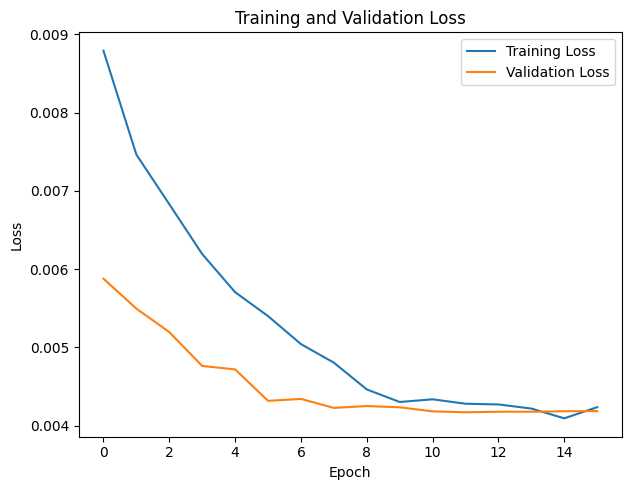

In [ ]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()



plt.tight_layout()
plt.show()

In [ ]:
# This code loads previously saved weights into the model defined above
# It is retained to allow evaluation of the model performance using the submitted weights
'''
from google.colab import files
import io

uploaded = files.upload()


weights_filename = list(uploaded.keys())[0]
print(f'File loades: {weights_filename}')

net.load_weights(weights_filename)
print('weights were successfully loaded')
'''

### Evaluation (on test set)

In [ ]:
# Apply the inverse Min-Max scaling to recover the age in real years
def minmax_unscale(y_norm, min_val, max_val):
    return y_norm * (max_val - min_val) + min_val

y_pred_norm = net.predict(X_test)

y_pred = minmax_unscale(y_pred_norm, age_min, age_max)


29/29 ━━━━━━━━━━━━━━━━━━━━ 30s 486ms/step


In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Test MAE (years):", mae)
print("Test RMSE (years):", rmse)
print("Test R2:", r2)


Test MAE (anni): 9.271834411501057
Test RMSE (anni): 11.689033932503946
Test R2: 0.2852357683703042


## ResNet

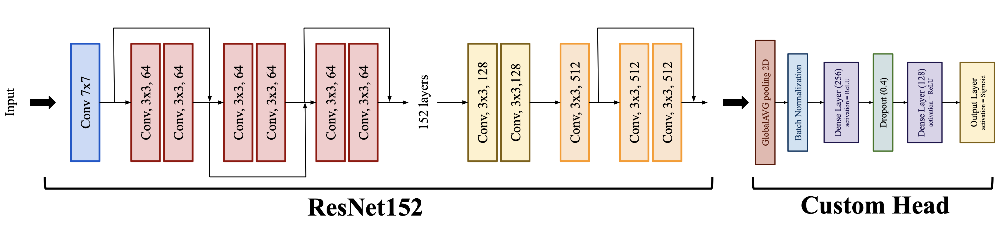

### Model Definition

In [ ]:
# Loading the ResNet152 architecture pre-trained on ImageNet
base_net = keras.applications.ResNet152(
    input_shape=(224,224,3),
    weights="imagenet",
    include_top=False # Excludes the original head (allowing the model to be adapted to a custom task)
)

base_net.trainable = False # freezing all layers of the backbone

234698864/234698864 ━━━━━━━━━━━━━━━━━━━━ 7s 0us/step


In [ ]:
# Defining the model input, grayscale images of size 100x100 (1 channel)
Inputs = keras.Input((100, 100, 1))

# Resizing images from 100x100 to 224x224 to match ResNet152 expected input size
x = layers.Resizing(224, 224)(Inputs)

# since EfficientNet was trained on 3-channel ImageNet images I convert grayscale images (1 channel) to RGB (3 channels)
x = layers.Lambda(lambda x: tf.image.grayscale_to_rgb(x))(x)

# Apply resNet preprocessing
x = keras.applications.resnet.preprocess_input(x)

# passing the preprocessed input through the frozen  backbone
x = base_net(x)

**Custom Head**

In [ ]:
# custom head
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.3)(x)
Outputs = layers.Dense(1, activation='sigmoid')(x)


net = keras.Model(Inputs, Outputs)
net.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resizing_2          │ (None, 224, 224,  │          0 │ input_layer_4[0]… │
│ (Resizing)          │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_2 (Lambda)   │ (None, 224, 224,  │          0 │ resizing_2[0][0]  │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_3          │ (None, 224, 224)  │          0 │ lambda_2[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_4          │ (None, 224, 224)  │          0 │ lambda_2[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_5          │ (None, 224, 224)  │          0 │ lambda_2[0][0]    │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack_1 (Stack)     │ (None, 224, 224,  │          0 │ get_item_3[0][0], │
│                     │ 3)                │            │ get_item_4[0][0], │
│                     │                   │            │ get_item_5[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 224, 224,  │          0 │ stack_1[0][0]     │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ resnet152           │ (None, 7, 7,      │ 58,370,944 │ add_1[0][0]       │
│ (Functional)        │ 2048)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 2048)      │          0 │ resnet152[1][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 2048)      │      8,192 │ global_average_p… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 256)       │    524,544 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 256)       │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 128)       │     32,896 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 128)       │          0 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 1)         │        129 │ dropout_5[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 58,936,705 (224.83 MB)

 Trainable params: 561,665 (2.14 MB)

 Non-trainable params: 58,375,040 (222.68 MB)

In [ ]:
net.compile(
    loss = keras.losses.Huber(delta=0.05),
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    metrics=[
        keras.metrics.MeanAbsoluteError(),
        keras.metrics.MeanSquaredError(),
        keras.metrics.RootMeanSquaredError()
    ]
)

**Callbacks**

In [ ]:
earlyStop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

**Training**

In [ ]:
history = net.fit(
    X_train_aug,
    y_train_norm,
    validation_split=0.2,
    batch_size=32,
    epochs=15,
    callbacks=[earlyStop, reduce_lr]
)

Epoch 1/15
166/166 ━━━━━━━━━━━━━━━━━━━━ 119s 520ms/step - loss: 0.0117 - mean_absolute_error: 0.2584 - mean_squared_error: 0.1049 - root_mean_squared_error: 0.3232 - val_loss: 0.0069 - val_mean_absolute_error: 0.1606 - val_mean_squared_error: 0.0415 - val_root_mean_squared_error: 0.2036 - learning_rate: 1.0000e-04
Epoch 2/15
166/166 ━━━━━━━━━━━━━━━━━━━━ 61s 370ms/step - loss: 0.0094 - mean_absolute_error: 0.2110 - mean_squared_error: 0.0720 - root_mean_squared_error: 0.2683 - val_loss: 0.0062 - val_mean_absolute_error: 0.1478 - val_mean_squared_error: 0.0358 - val_root_mean_squared_error: 0.1892 - learning_rate: 1.0000e-04
Epoch 3/15
166/166 ━━━━━━━━━━━━━━━━━━━━ 59s 356ms/step - loss: 0.0080 - mean_absolute_error: 0.1837 - mean_squared_error: 0.0561 - root_mean_squared_error: 0.2369 - val_loss: 0.0061 - val_mean_absolute_error: 0.1446 - val_mean_squared_error: 0.0339 - val_root_mean_squared_error: 0.1842 - learning_rate: 1.0000e-04
Epoch 4/15
166/166 ━━━━━━━━━━━━━━━━━━━━ 59s 358ms/step

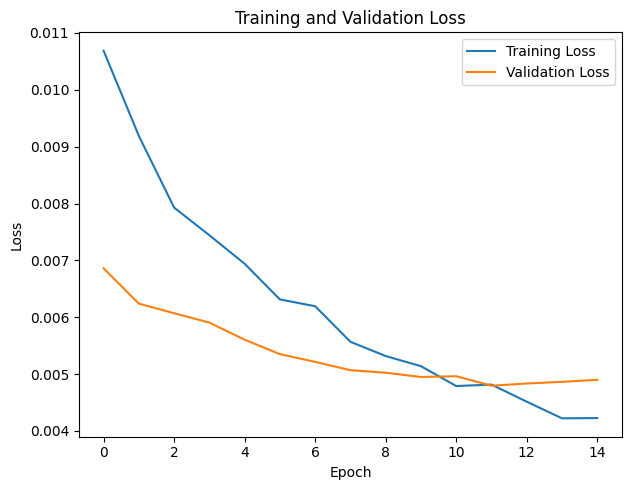

In [ ]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()



plt.tight_layout()
plt.show()

In [ ]:
# This code loads previously saved weights into the model defined above
# It is retained to allow evaluation of the model performance using the submitted weights
'''
from google.colab import files
import io

uploaded = files.upload()


weights_filename = list(uploaded.keys())[0]
print(f'File loades: {weights_filename}')

net.load_weights(weights_filename)
print('weights were successfully loaded')
'''

### Evaluation (on test set)

In [ ]:
# Apply the inverse Min-Max scaling to recover the age in real years
def minmax_unscale(y_norm, min_val, max_val):
    return y_norm * (max_val - min_val) + min_val

y_pred_norm = net.predict(X_test)
y_pred = minmax_unscale(y_pred_norm, age_min, age_max)

29/29 ━━━━━━━━━━━━━━━━━━━━ 9s 296ms/step


In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Test MAE (years):", mae)
print("Test RMSE (years):", rmse)
print("Test R2:", r2)


Test MAE (anni): 9.851965619362892
Test RMSE (anni): 12.536341978317424
Test R2: 0.1778572449045298


# Multitasking learning Approach

## Model - Multitask

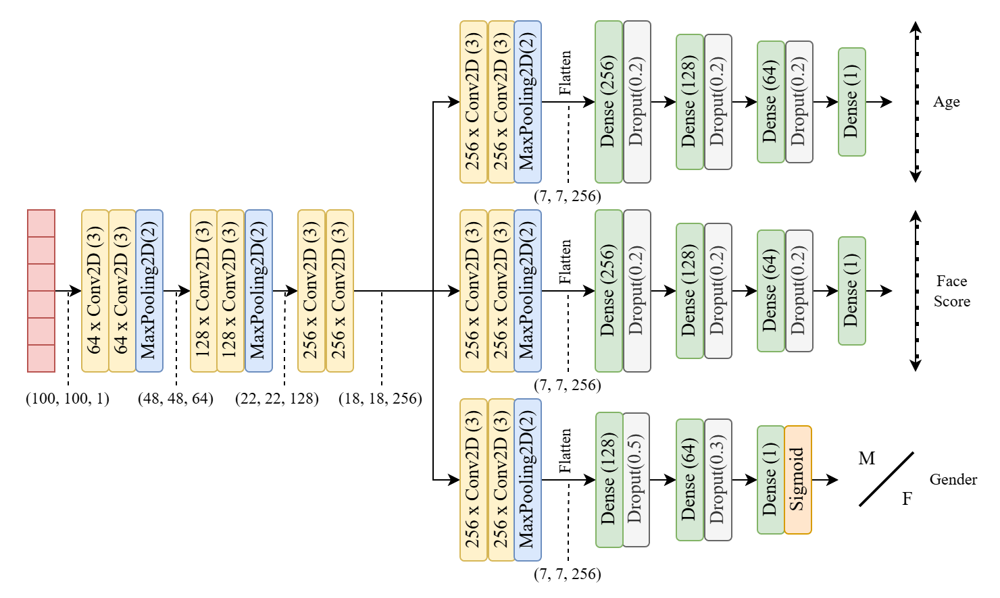

In [ ]:
# Input
Inputs = keras.layers.Input(shape=(100,100,1))

# Shared hidden layers
x = keras.layers.Conv2D(64,3,activation="relu")(Inputs)

# Testing the usage of BN
# Empirically it did not work well
# That is why these layers are all commented out
#
#x = keras.layers.BatchNormalization()(x)
x = keras.layers.Conv2D(64,3, activation="relu")(x)
#x = keras.layers.BatchNormalization()(x)
x = keras.layers.MaxPooling2D(2)(x)

x = keras.layers.Conv2D(128,3,activation="relu")(x)
x = keras.layers.Conv2D(128,3, activation="relu")(x)
x = keras.layers.MaxPooling2D(2)(x)

x = keras.layers.Conv2D(256,3,activation="relu")(x)
Output_shared = keras.layers.Conv2D(256,3, activation="relu")(x)

# ---------- Subject-specific branches ----------

# Task 1
age = keras.layers.Conv2D(256, 3, activation="relu")(Output_shared)
#age = keras.layers.BatchNormalization()(age)
age = keras.layers.Conv2D(256, 3, activation="relu")(age)
#age = keras.layers.BatchNormalization()(age)
age = keras.layers.MaxPooling2D(2)(age)

age = keras.layers.Flatten()(age)
age = keras.layers.Dropout(0.2)(age)
age = keras.layers.Dense(256, activation="relu")(age)
age = keras.layers.Dropout(0.2)(age)
age = keras.layers.Dense(128, activation="relu")(age)
age = keras.layers.Dropout(0.2)(age)
age = keras.layers.Dense(64, activation="relu")(age)
Output_age  = keras.layers.Dense(1, activation="linear", name="age")(age)

# Task 2
gender = keras.layers.Conv2D(256, 3, activation="relu")(Output_shared)
#gender = keras.layers.BatchNormalization()(gender)
gender = keras.layers.Conv2D(256, 3, activation="relu")(gender)
#gender = keras.layers.BatchNormalization()(gender)
gender = keras.layers.MaxPooling2D(2)(gender)

gender = keras.layers.Flatten()(gender)
gender = keras.layers.Dropout(0.5)(gender)
gender = keras.layers.Dense(128, activation="relu")(gender)
gender = keras.layers.Dropout(0.3)(gender)
gender = keras.layers.Dense(64, activation="relu")(gender)
Output_gender = keras.layers.Dense(1, activation="sigmoid", name="gender")(gender)

# Task 3
face_score = keras.layers.Conv2D(256, 3, activation="relu")(Output_shared)
#face_score = keras.layers.BatchNormalization()(face_score)
face_score = keras.layers.Conv2D(256, 3, activation="relu")(face_score)
#face_score = keras.layers.BatchNormalization()(face_score)
face_score = keras.layers.MaxPooling2D(2)(face_score)

face_score = keras.layers.Flatten()(face_score)
face_score = keras.layers.Dropout(0.2)(face_score)
face_score = keras.layers.Dense(256, activation="relu")(face_score)
face_score = keras.layers.Dropout(0.2)(face_score)
face_score = keras.layers.Dense(128, activation="relu")(face_score)
face_score = keras.layers.Dropout(0.2)(face_score)
face_score = keras.layers.Dense(64, activation="relu")(face_score)
Output_face_score = keras.layers.Dense(1, activation="linear", name="face_score")(face_score)

# Model
multi_task_model = keras.Model(
    Inputs,
    outputs=[Output_age, Output_gender, Output_face_score],
)

multi_task_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 98, 98,    │        640 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 96, 96,    │     36,928 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 48, 48,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 46, 46,    │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 44, 44,    │    147,584 │ conv2d_2[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 22, 22,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 20, 20,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 18, 18,    │    590,080 │ conv2d_4[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │    590,080 │ conv2d_5[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 16, 16,    │    590,080 │ conv2d_5[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 14, 14,    │    590,080 │ conv2d_6[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 14, 14,    │    590,080 │ conv2d_10[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 7, 7, 256) │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 16, 16,    │    590,080 │ conv2d_5[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 7, 7, 256) │          0 │ conv2d_11[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 12544)     │          0 │ max_pooling2d_2[

 Total params: 12,804,291 (48.84 MB)

 Trainable params: 12,804,291 (48.84 MB)

 Non-trainable params: 0 (0.00 B)

**Model visualization**

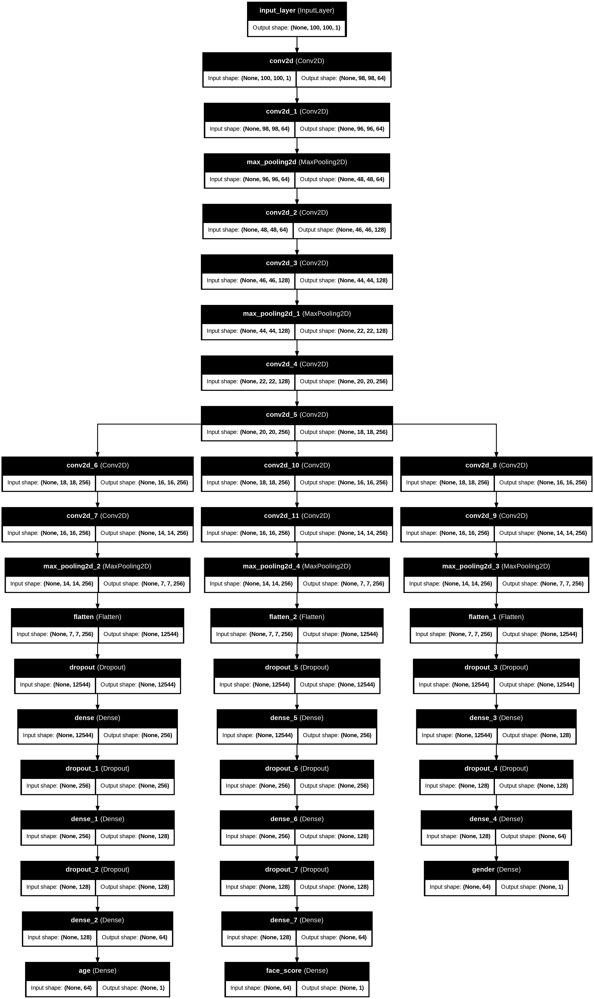

In [ ]:
from tensorflow.keras.utils import plot_model

plot_model(multi_task_model, to_file='mtl_model.png', show_shapes=True, show_layer_names=True, rankdir='TD')

### Data Preparation

**Pixel Normalization**

(array([2896026.,  605345.,  418145.,  614265.,  385732.,  614094.,
         401665.,  634947.,  425533.,  656400.,  657107.,  444521.,
         678106.,  456851.,  695075.,  476236.,  721666.,  485211.,
         742392.,  504540.,  766086.,  778361.,  526887.,  809376.,
         546908.,  830996.,  557917.,  853615.,  580238.,  871258.,
         884814.,  600729.,  915905.,  620430.,  945319.,  641579.,
         975589.,  657029.,  998524.,  672540., 1017526., 1026726.,
         688010., 1040587.,  696616., 1049303.,  701704., 1055451.,
         705754., 1061403., 1064179.,  707829., 1054830.,  699605.,
        1051531.,  694013., 1023557.,  677162., 1002884.,  661449.,
         976109.,  962366.,  633560.,  936969.,  613494.,  901937.,
         583260.,  856802.,  557286.,  812025.,  793385.,  504042.,
         737691.,  471815.,  681254.,  433401.,  626776.,  400804.,
         577550.,  370972.,  536038.,  513378.,  316280.,  451955.,
         290790.,  415335.,  264484.,  377360., 

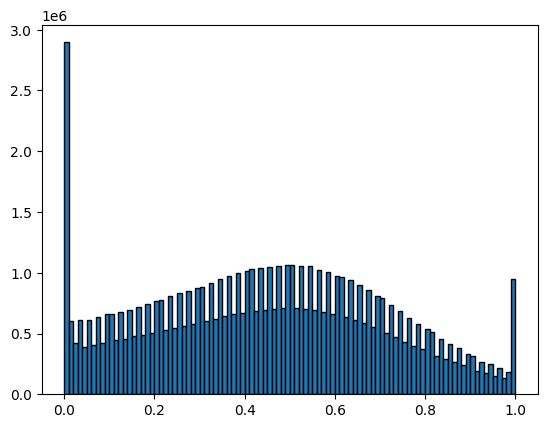

In [ ]:
# Changing type to float32
X_train_aug_norm = X_train_aug.astype('float32')
X_test_norm = X_test.astype('float32')

# Train and Test images normalization
X_train_aug_norm = X_train_aug_norm / 255.0
X_test_norm = X_test_norm / 255.0

# Plotting the new pixel value distribution, w.r.t. the train images
plt.hist(X_train_aug.flatten(), bins=100, edgecolor='black')

**Min-Max Age Scaling**

(array([86.,  0.,  0., 86., 86., 86., 86.,  0., 86., 86., 86., 86., 86.,
        86., 86.,  0., 86., 86., 86., 86., 86., 86., 86.,  0., 86., 86.,
        86., 86., 86., 86.,  0., 86., 86., 86., 86., 86., 86., 86.,  0.,
        86., 86., 86., 86., 86., 86., 86.,  0., 86., 86., 86., 86., 86.,
        86.,  0., 86., 86., 86., 86., 86., 86., 86.,  0., 86., 86., 86.,
        86., 86., 86., 86.,  0., 86., 86., 86., 86., 86., 86.,  0., 86.,
        86., 86.,  0., 86., 86., 86.,  0., 86., 86.,  0., 86.,  0., 86.,
         0.,  0.,  0.,  0., 86.,  0.,  0.,  0., 86.]),
 array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
        0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
        0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
        0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
        0.44, 0.45, 0.46, 0.47, 0.48, 0.49, 0.5 , 0.51, 0.52, 0.53, 0.54,
        0.55, 0.56, 0.57, 0.58, 0.59, 0.6 , 0.61, 0.62, 0.63, 0.

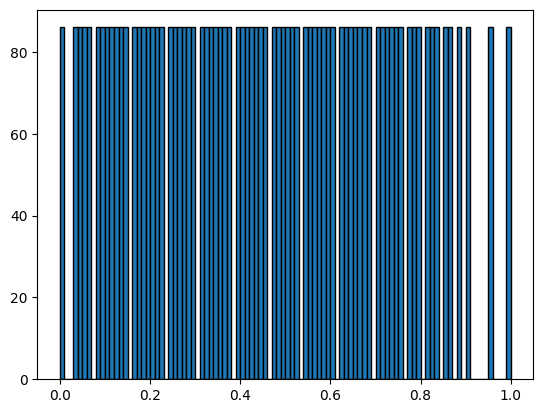

In [ ]:
# Calculating the Min and Max ages in the training set
y_train_aug_min = np.min(y_train_aug)
y_train_aug_max = np.max(y_train_aug)

# Scaling the age w.r.t. the Min and Max values calculated before
y_train_aug_norm = (y_train_aug - y_train_aug_min) / (y_train_aug_max - y_train_aug_min)
y_test_norm = (y_test - y_train_aug_min) / (y_train_aug_max - y_train_aug_min)

# Plotting new age distribution in the training set
plt.hist(y_train_aug_norm.flatten(), bins=100, edgecolor='black')

**Min-Max Face Score Scaling**

(array([334., 293., 254., 200., 163., 178., 230., 216., 195., 128., 185.,
        124., 212., 109., 157., 148., 100., 123., 185., 264.,  81., 179.,
        133., 139., 121., 159., 150.,  70.,  86.,  96., 109.,  50., 138.,
         51.,  74.,  69.,  76.,  42.,  45., 153.,  91.,  37.,  27.,  43.,
         34.,  33.,  62.,  24.,  27.,  31.,  20.,  56.,  16.,  21.,  13.,
         15.,  21.,  64.,  13.,   3.,   3.,  12.,  10.,  19.,  12.,   5.,
         10.,   2.,  10.,   6.,   6.,   3.,  19.,  10.,   1.,   1.,   3.,
          0.,   2.,   0.,   1.,   0.,   0.,   5.,   3.,   0.,   1.,   0.,
          0.,   1.,   0.,   0.,   0.,   2.,   0.,   0.,   0.,   0.,   0.,
          5.]),
 array([0.  , 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1 ,
        0.11, 0.12, 0.13, 0.14, 0.15, 0.16, 0.17, 0.18, 0.19, 0.2 , 0.21,
        0.22, 0.23, 0.24, 0.25, 0.26, 0.27, 0.28, 0.29, 0.3 , 0.31, 0.32,
        0.33, 0.34, 0.35, 0.36, 0.37, 0.38, 0.39, 0.4 , 0.41, 0.42, 0.43,
        0.44, 0.45, 0.

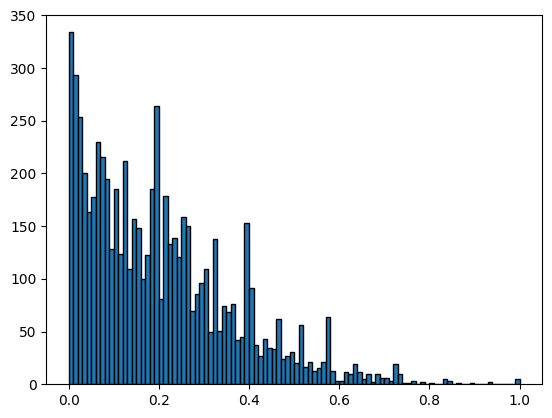

In [ ]:
# Calculating Min and Max face scores in the training set
face_score_aug_min = np.min(train_face_score_aug)
face_score_aug_max = np.max(train_face_score_aug)

# Scaling the face scores w.r.t. the Min and Max values calculated before
train_face_score_aug_norm = (train_face_score_aug - face_score_aug_min) / (face_score_aug_max - face_score_aug_min)
test_face_score_aug_norm = (test_face_score - face_score_aug_min) / (face_score_aug_max - face_score_aug_min)

# Plotting the new face score distribution in the training set
plt.hist(train_face_score_aug_norm.flatten(), bins=100, edgecolor='black')

### Short Training for Loss Balance Assessment

In [ ]:
multi_task_model.compile(
    optimizer=keras.optimizers.Adam(0.001),
    loss=[
        keras.losses.MeanAbsoluteError(),
        keras.losses.BinaryCrossentropy(),
        keras.losses.MeanAbsoluteError()],
    metrics=[['mse', 'mae'], ['accuracy'], ['mse', 'mae']],
    loss_weights=[1.0, 1.0, 1.0])

callback = keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 4, min_delta = 0.001, restore_best_weights = True)


In [ ]:
history_mt = multi_task_model.fit(
    X_train_aug_norm,
    [y_train_aug_norm, train_gender_aug, train_face_score_aug_norm],
    validation_split = 0.2,
    epochs = 3,
    batch_size = 32,
    callbacks=[callback])

Epoch 1/3
166/166 ━━━━━━━━━━━━━━━━━━━━ 63s 203ms/step - age_loss: 0.4625 - age_mae: 0.4625 - age_mse: 0.5981 - face_score_loss: 0.6562 - face_score_mae: 0.6562 - face_score_mse: 1.7384 - gender_accuracy: 0.5816 - gender_loss: 0.7430 - loss: 1.8617 - val_age_loss: 0.2416 - val_age_mae: 0.2420 - val_age_mse: 0.0852 - val_face_score_loss: 0.1902 - val_face_score_mae: 0.1910 - val_face_score_mse: 0.0593 - val_gender_accuracy: 0.5819 - val_gender_loss: 0.6822 - val_loss: 1.1163
Epoch 2/3
166/166 ━━━━━━━━━━━━━━━━━━━━ 43s 73ms/step - age_loss: 0.2612 - age_mae: 0.2612 - age_mse: 0.1103 - face_score_loss: 0.1963 - face_score_mae: 0.1963 - face_score_mse: 0.0820 - gender_accuracy: 0.6351 - gender_loss: 0.6654 - loss: 1.1229 - val_age_loss: 0.3090 - val_age_mae: 0.3093 - val_age_mse: 0.1487 - val_face_score_loss: 1.4716 - val_face_score_mae: 1.4737 - val_face_score_mse: 2.3217 - val_gender_accuracy: 0.6038 - val_gender_loss: 2.0182 - val_loss: 3.8130
Epoch 3/3
166/166 ━━━━━━━━━━━━━━━━━━━━ 13s 77

In [ ]:
# Average losses
avg_loss_age = np.mean(history_mt.history['age_loss'])
avg_loss_gender = np.mean(history_mt.history['gender_loss'])
avg_loss_face_score = np.mean(history_mt.history['face_score_loss'])

print(avg_loss_age)
print(avg_loss_gender)
print(avg_loss_face_score)

0.2239419249817729
0.34273978462442756
0.14847376360557973


### Actual MTL Model Training

In [ ]:
multi_task_model.compile(
    optimizer=keras.optimizers.Adam(0.0001),
    loss=[
        keras.losses.MeanAbsoluteError(),
        keras.losses.BinaryCrossentropy(),
        keras.losses.MeanAbsoluteError()],
    metrics=[['mse', 'mae'], ['accuracy'], ['mse', 'mae']],
    loss_weights={'age': 2, 'gender': 0.5, 'face_score': 1.5})

callback = keras.callbacks.EarlyStopping(monitor = 'val_age_loss', mode="min", patience = 5, min_delta = 0.001, restore_best_weights = True)

In [ ]:
history_mt = multi_task_model.fit(
    X_train_aug_norm,
    [y_train_aug_norm, train_gender_aug, train_face_score_aug_norm],
    validation_split = 0.2,
    epochs = 50,
    batch_size = 32,
    callbacks=[callback])

Epoch 1/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 45s 181ms/step - age_loss: 0.2740 - age_mae: 0.2740 - age_mse: 0.1100 - face_score_loss: 0.1403 - face_score_mae: 0.1403 - face_score_mse: 0.0343 - gender_accuracy: 0.6284 - gender_loss: 0.6696 - loss: 1.6225 - val_age_loss: 0.2249 - val_age_mae: 0.2257 - val_age_mse: 0.0692 - val_face_score_loss: 0.1286 - val_face_score_mae: 0.1286 - val_face_score_mse: 0.0284 - val_gender_accuracy: 0.6038 - val_gender_loss: 0.6786 - val_loss: 1.5362
Epoch 2/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 18s 110ms/step - age_loss: 0.2151 - age_mae: 0.2151 - age_mse: 0.0685 - face_score_loss: 0.1307 - face_score_mae: 0.1307 - face_score_mse: 0.0290 - gender_accuracy: 0.6294 - gender_loss: 0.6619 - loss: 1.4884 - val_age_loss: 0.2014 - val_age_mae: 0.2018 - val_age_mse: 0.0629 - val_face_score_loss: 0.1285 - val_face_score_mae: 0.1285 - val_face_score_mse: 0.0282 - val_gender_accuracy: 0.6038 - val_gender_loss: 0.6779 - val_loss: 1.4870
Epoch 3/50
166/166 ━━━━━━━━━━━━━━━━━━━━ 18

**Plotting the learning curves**

Text(0.5, 0, 'Epoch')

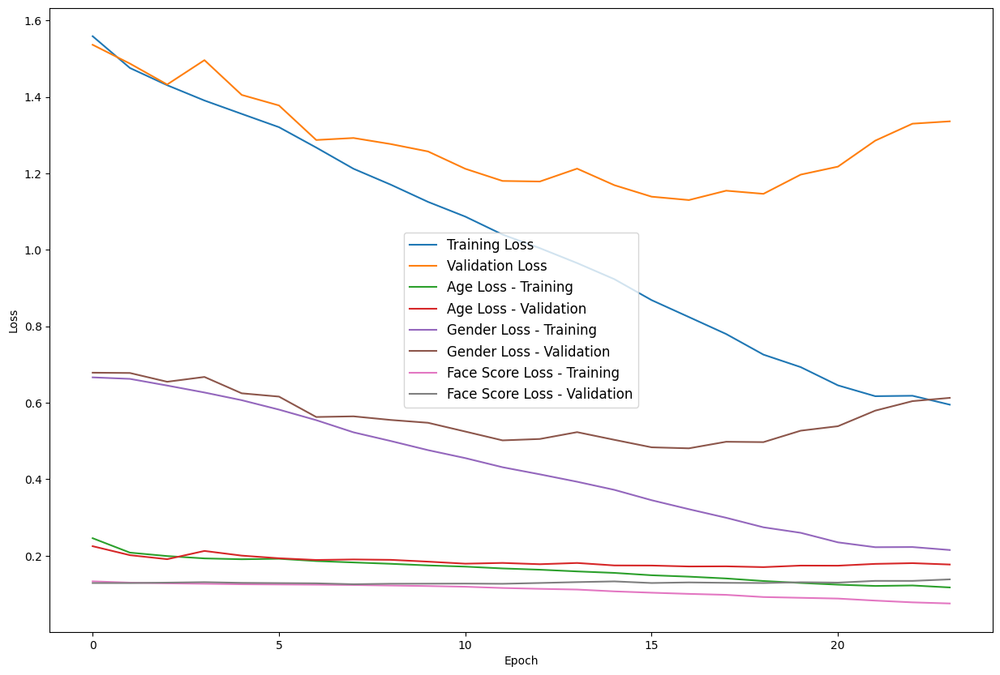

In [ ]:
fig = plt.figure(figsize=(15, 10))
plt.plot(history_mt.history['loss'], label='Training Loss')
plt.plot(history_mt.history['val_loss'], label='Validation Loss')
plt.plot(history_mt.history['age_loss'], label='Age Loss - Training')
plt.plot(history_mt.history['val_age_loss'], label='Age Loss - Validation')
plt.plot(history_mt.history['gender_loss'], label='Gender Loss - Training')
plt.plot(history_mt.history['val_gender_loss'], label='Gender Loss - Validation')
plt.plot(history_mt.history['face_score_loss'], label='Face Score Loss - Training')
plt.plot(history_mt.history['val_face_score_loss'], label='Face Score Loss - Validation')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(fontsize = 12)
plt.xlabel('Epoch')

**Plotting the weighted learning curves**

Text(0.5, 1.0, 'Losses Rescaled by the Corresponding Weights')

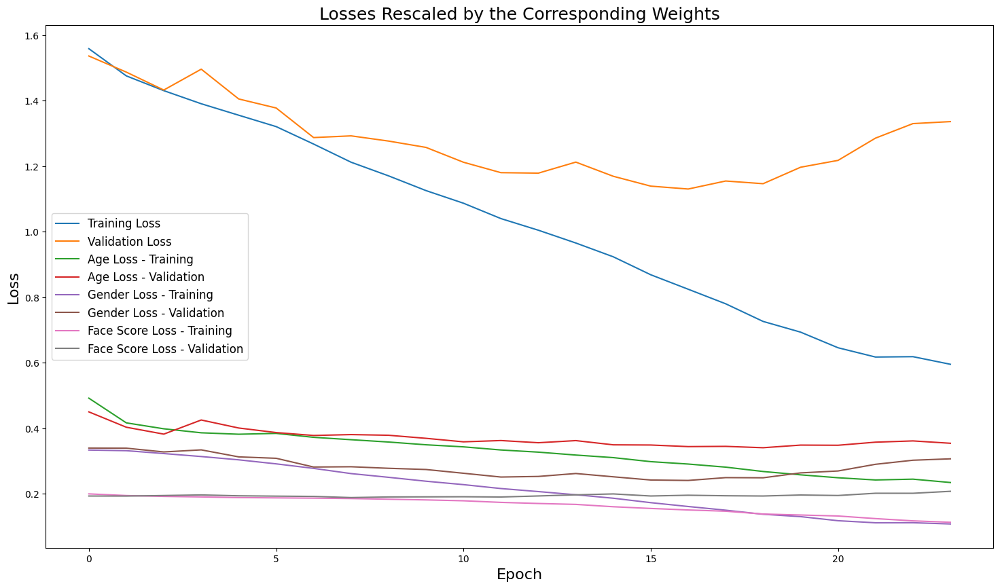

In [ ]:
fig = plt.figure(figsize=(18, 10))
plt.plot(np.array(history_mt.history['loss']), label='Training Loss')
plt.plot(np.array(history_mt.history['val_loss']), label='Validation Loss')
plt.plot(2 * np.array(history_mt.history['age_loss']), label='Age Loss - Training')
plt.plot(2 * np.array(history_mt.history['val_age_loss']), label='Age Loss - Validation')
plt.plot(0.5 * np.array(history_mt.history['gender_loss']), label='Gender Loss - Training')
plt.plot(0.5 * np.array(history_mt.history['val_gender_loss']), label='Gender Loss - Validation')
plt.plot(1.5 * np.array(history_mt.history['face_score_loss']), label='Face Score Loss - Training')
plt.plot(1.5 * np.array(history_mt.history['val_face_score_loss']), label='Face Score Loss - Validation')
plt.xlabel('Epoch', fontsize = 16)
plt.ylabel('Loss', fontsize = 16)
plt.legend(fontsize = 12)
plt.title("Losses Rescaled by the Corresponding Weights", fontsize = 18)

### Evaluation

In [ ]:
# Age predictions (to be Unnormalized )
y_pred_norm_mtl = multi_task_model.predict(X_test_norm)[0].flatten()

# Unnormalized age predictions
y_pred_mtl = minmax_unscale(y_pred_norm_mtl, age_min, age_max)

# Evaluation metrics
mae = mean_absolute_error(y_test, y_pred_mtl)
mse = mean_squared_error(y_test, y_pred_mtl)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_mtl)

print("Test MAE (years):", mae)
print("Test RMSE (years):", rmse)
print("Test R2:", r2)

29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step
Test MAE (years): 9.887433088173468
Test RMSE (years): 12.871067623012681
Test R2: 0.10201891386805584


# SSL Approach

## Reconstruction Task - TensorFlow Dataset definition

**Images normalization**

In [ ]:
X_train_aug_norm = np.memmap("X_train_aug_norm.npy", dtype="float32", mode="w+", shape=X_train_aug.shape)
X_train_aug_norm[:] = (X_train_aug.astype("float32") / 255.0)
X_train_aug_norm.flush()

In [ ]:
X_test_norm = np.memmap("X_test_norm.npy", dtype="float32", mode="w+", shape=X_test.shape)
X_test_norm[:] = (X_test.astype("float32") / 255.0)
X_test_norm.flush()

**Cropping function**

Designed with the purpose to highlight the facial traits.

In [ ]:
def cropping_transformation(X):

  cropped = keras.layers.Cropping2D(cropping=((25,25),(25,25)))(X)
  cropped = keras.layers.Resizing(100, 100)(cropped)

  cropped = cropped.numpy()

  return cropped

**Cropping Train and Test images**

In [ ]:
X_train_aug_norm_cropped = np.memmap("X_train_aug_norm_resized.npy", dtype="float32", mode="w+", shape=X_train_aug_norm.shape)
X_train_aug_norm_cropped[:] = cropping_transformation(X_train_aug_norm)
X_train_aug_norm_cropped.flush()

In [ ]:
X_test_norm_cropped = np.memmap("X_test_norm_resized.npy", dtype="float32", mode="w+", shape=X_test_norm.shape)
X_test_norm_cropped[:] = cropping_transformation(X_test_norm)
X_test_norm_cropped.flush()

**TensorFlow Dataset creation**

TensorFlow Dataset via generator function in order to save memory.

In [ ]:
# x_ae = X_train_aug_norm_resized[:100]
# val_ae = X_test_norm_resized[:100]
# batch_size = 1
x_ae = X_train_aug_norm_cropped
val_ae = X_test_norm_cropped
batch_size_ae = 64

In [ ]:
# Train TF Dataset generator function
def train_generator_ae():
    for i in range(0, len(x_ae), batch_size_ae):
        yield x_ae[i:i+batch_size_ae]

# Validation TF Dataset generator function
def test_generator_ae():
    for i in range(0, len(val_ae), batch_size_ae):
        yield val_ae[i:i+batch_size_ae]


In [ ]:
# Train TF Dataset
train_dataset_ae = tf.data.Dataset.from_generator(
    train_generator_ae,
    output_signature=tf.TensorSpec(shape=(None, 100, 100, 1), dtype=tf.float32)
)

# Validation TF Dataset
test_dataset_ae = tf.data.Dataset.from_generator(
    test_generator_ae,
    output_signature=(
        tf.TensorSpec(shape=(None, 100, 100, 1), dtype=tf.float32)
))

# Use the following code instead, if you wish to load all the dataset in memory at once
"""
train_dataset_ae = tf.data.Dataset.from_tensor_slices(x_ae)
train_dataset_ae = train_dataset_ae.batch(batch_size)
train_dataset_ae = train_dataset_ae.prefetch(buffer_size=tf.data.AUTOTUNE)

test_dataset_ae = tf.data.Dataset.from_tensor_slices(val_ae)
test_dataset_ae = test_dataset_ae.batch(batch_size)
test_dataset_ae = test_dataset_ae.prefetch(buffer_size=tf.data.AUTOTUNE)
"""

'\ntrain_dataset_ae = tf.data.Dataset.from_tensor_slices(x_ae)\ntrain_dataset_ae = train_dataset_ae.batch(batch_size)\ntrain_dataset_ae = train_dataset_ae.prefetch(buffer_size=tf.data.AUTOTUNE)\n\ntest_dataset_ae = tf.data.Dataset.from_tensor_slices(val_ae)\ntest_dataset_ae = test_dataset_ae.batch(batch_size) \ntest_dataset_ae = test_dataset_ae.prefetch(buffer_size=tf.data.AUTOTUNE)\n'

**Visualizing the training reconstruction-task images**

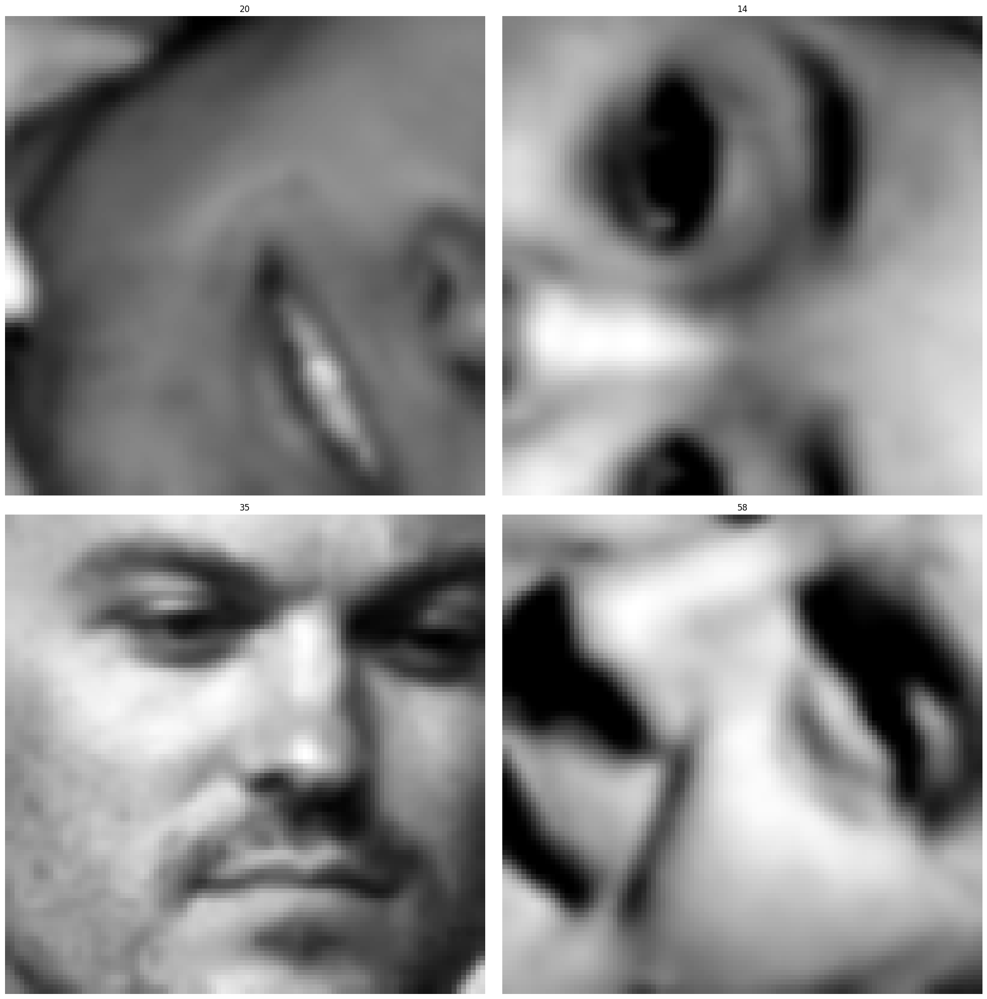

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(20, 20))
for i, ax in enumerate(axes.flat):
    random_index = i
    ax.imshow(X_train_aug_norm_cropped[random_index],cmap="gray")
    ax.set_title(f'{y_train_aug[random_index]:.0f}') # Display age label, formatted as integer
    ax.axis('off')
plt.tight_layout()

## Downstream Task - TensorFlow Dataset definition

**Min-Max Age Scaling**

In [ ]:
age_min = y_train_aug.min()
age_max = y_train_aug.max()

y_train_aug_norm = np.memmap("y_train_aug_norm.npy", dtype="float32", mode="w+", shape=y_train_aug.shape)
y_train_aug_norm[:] = minmax_scale(y_train_aug, age_min, age_max)
y_train_aug_norm.flush()

print(f"y_train_aug_norm range : [{y_train_aug_norm.min()}, {y_train_aug_norm.max()}]")

y_train_aug_norm range : [0.0, 1.0]


**TensorFlow Dataset creation**

TensorFlow Dataset via generator function in order to save memory.

In [ ]:
# Train/Validation splitting
train_sample = int(0.7 * len(X_train_aug_norm))

# Train set
x_train_fn = X_train_aug_norm[:train_sample]
y_train_fn = y_train_aug_norm[:train_sample]

# Validation set
x_test_fn = X_train_aug_norm[train_sample:]
y_test_fn = y_train_aug_norm[train_sample:]

# Batch size
batch_size_fn = 128

In [ ]:
# Train TF Dataset generator function
def train_generator_fn():
    for i in range(0, len(x_train_fn), batch_size_fn):
        yield x_train_fn[i:i+batch_size_fn] , y_train_fn[i:i+batch_size_fn]

# Validation TF Dataset generator function
def test_generator_fn():
    for i in range(0, len(x_test_fn), batch_size_fn):
        yield x_test_fn[i:i+batch_size_fn], y_test_fn[i:i+batch_size_fn]

In [ ]:
# Train TF Dataset
train_dataset_fn = tf.data.Dataset.from_generator(
    train_generator_fn,
    output_signature=(
        tf.TensorSpec(shape=(None, 100, 100, 1), dtype=tf.float32),
        tf.TensorSpec(shape=(None,), dtype=y_train_fn.dtype),
    )
)

# Validation TF Dataset
val_dataset_fn = tf.data.Dataset.from_generator(
    test_generator_fn,
    output_signature=(
        tf.TensorSpec(shape=(None, 100, 100, 1), dtype=tf.float32),
        tf.TensorSpec(shape=(None,), dtype=y_test_fn.dtype),
    )
)

'\ntrain_dataset_fn = tf.data.Dataset.from_tensor_slices((x_train_fn, y_train_fn))\ntrain_dataset_fn = train_dataset_fn.batch(batch_size) # Changed batch size back to 32\ntrain_dataset_fn = train_dataset_fn.prefetch(buffer_size=tf.data.AUTOTUNE)\n'

## Training Callbacks

In [ ]:
# Early stopping callback
earlyStop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Reduce learning rate when the validation loss stops improving
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

In [ ]:
# Callback used to monitor the progressive improvement made by the Autoencoder
# epoch after epoch in the image reconstruction task
from keras.callbacks import LambdaCallback
import sys
import matplotlib.pyplot as plt

def reconstructionAfterEpoch(epoch, _):

  rows = 2   # total rows
  cols = 2   # images per row

  fig, axes = plt.subplots(rows, cols, figsize=(8, 8))

  # List of images to reconstruct
  images = []

  # Retriving the first four images of the validation set
  for x_batch in test_dataset_ae:
      for img in x_batch:
          images.append(img)
          if len(images) == 4:
              break
      if len(images) == 4:
          break
  four_images = tf.stack(images)

  # Image reconstruction at the end of the current epoch
  img_pred = autoencoder_densenet(four_images, training=False)

  # Displaying the reconstruction results
  #
  # Row 0: the original images
  # Row 1: the respective reconstructed images
  for row in range(rows):
      for col in range(cols):
          base_idx = (row // 2) * cols
          idx = base_idx + col

          if row % 2 == 0:
              # original image
              img = four_images[idx]
          else:
              # prediction
              img = img_pred[idx]

          # displaying the current image [img]
          axes[row, col].imshow(img, cmap="gray")

          axes[row, col].axis("off")

  plt.tight_layout()
  plt.show()

reconstruction_callback = LambdaCallback(on_epoch_end=reconstructionAfterEpoch)

## Pretext task

**Autoencoder class definition**

In [ ]:
# Class structure from https://keras.io/examples/generative/vae/

class AE(keras.Model):
    def __init__(self, encoder, decoder, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.loss_tracker = keras.metrics.Mean(name="loss")
        self.loss_fn = keras.losses.MeanSquaredError()

    @property
    def metrics(self):
        return [
            self.loss_tracker
        ]

    def call(self, inputs, training=False):
        x = self.encoder(inputs, training=training)
        reconstruction = self.decoder(x)
        return reconstruction

    def compute_loss(self, x, y, y_pred, sample_weight=None):

        reconstruction_loss = self.loss_fn(x, y_pred)
        loss = reconstruction_loss
        self.loss_tracker.update_state(loss)
        return loss

    def train_step(self, data):
        with tf.GradientTape() as tape:
            reconstruction = self(data, training=True)
            reconstruction_loss = self.loss_fn(data, reconstruction)
            loss = reconstruction_loss

        grads = tape.gradient(loss, self.trainable_weights)
        self.optimizer.apply_gradients(zip(grads, self.trainable_weights))
        self.loss_tracker.update_state(loss)
        return {
            "loss": self.loss_tracker.result()
        }


### DenseNet-like Encoder Definition

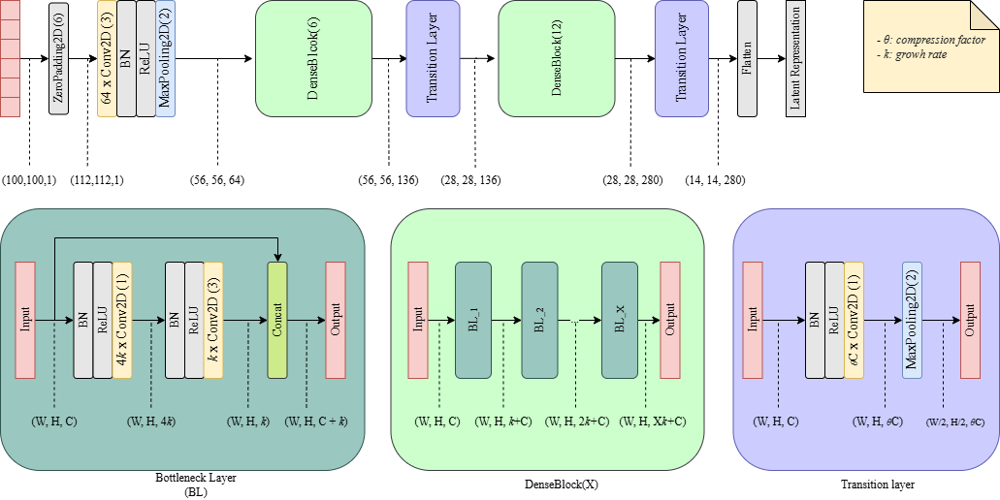

**Dense "bottleneck" layer function**

In [ ]:
# Each dense block keps the spatial dimension of the input unchanged (so stride = 1 and padding = 'same')
def dense_layer(x, growth_rate, block_num, layer_num):
    # bottleneck
    x1 = keras.layers.BatchNormalization()(x)
    x1 = keras.layers.ReLU()(x1)
    x1 = keras.layers.Conv2D(4 * growth_rate, 1, padding="same", activation="linear", name="conv_1_dense_block_"+str(block_num)+"_layer_num_"+str(layer_num))(x1)

    # 3x3 conv "bottleneck"
    x1 = keras.layers.BatchNormalization()(x1)
    x1 = keras.layers.ReLU()(x1)
    x1 = keras.layers.Conv2D(growth_rate, 3, padding="same", activation="linear", name="conv_3_dense_block_"+str(block_num)+"_layer_num_"+str(layer_num))(x1)

    # input-output concatenation
    x = keras.layers.Concatenate(name="contcat_block_"+str(block_num)+"_layer_num_"+str(layer_num))([x, x1])
    return x


**Dense block function**

Implemented as a sequence of bottleneck layers



In [ ]:
def dense_block(x, num_layers, growth_rate, block_num):
    for l in range(num_layers):
        x = dense_layer(x, growth_rate, block_num, l)
    return x


**Transition layers function**

In [ ]:
def transition_layer(x, compression=0.5):
    # This number of filters enables the resizing of the input along the depth dimension
    # (depending on the value of the compression factor [compression])
    filters = int(tf.keras.backend.int_shape(x)[-1] * compression)

    x = keras.layers.BatchNormalization()(x)
    x = keras.layers.ReLU()(x)
    x = keras.layers.Conv2D(filters, 1, padding="same", activation="linear")(x)

    # The final pooling layer enables the resizing of the input along the spatial dimension.
    # Here the avarage pooling has been replaced by the max pooling, to seek for sharper reconstruction results
    x = keras.layers.MaxPooling2D(2, strides=2)(x)
    return x


**Encoder Definition**

In [ ]:
input_shape=(100, 100, 1)
growth_rate=12
compression=1

inputs = keras.layers.Input(shape=input_shape)

# Initial convolution
x = keras.layers.ZeroPadding2D(6)(inputs)
x = keras.layers.Conv2D(64, 3, strides=1, padding="same")(x)
x = keras.layers.BatchNormalization()(x)
x = keras.layers.ReLU()(x)
x = keras.layers.MaxPooling2D(2)(x)  # output shape at this stage: 56x56

# Dense blocks (inspired by DenseNet-121 structure)

# DenseBlock1
x = dense_block(x, num_layers=6,  growth_rate=growth_rate, block_num=0)
x = transition_layer(x, compression) # output shape at this stage: 56x56

# DenseBlock2
x = dense_block(x, num_layers=12, growth_rate=growth_rate, block_num=1)
out_last_block = transition_layer(x, compression) # output shape at this stage: 56x56

# Flattening
out_densnet = layers.Flatten()(out_last_block)

# Encoder definition
encoder = keras.Model(inputs, out_densnet, name="encoder")
encoder.summary()

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 100, 100,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 112, 112,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 112, 112,  │        640 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 112, 112,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 112, 112,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 56, 56,    │          0 │ re_lu[0][0]       │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        256 │ max_pooling2d[0]… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_1_dense_block… │ (None, 56, 56,    │      3,120 │ re_lu_1[0][0]     │
│ (Conv2D)            │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        192 │ conv_1_dense_blo… │
│ (BatchNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_2 (ReLU)      │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_3_dense_block… │ (None, 56, 56,    │      5,196 │ re_lu_2[0][0]     │
│ (Conv2D)            │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ contcat_block_0_la… │ (None, 56, 56,    │          0 │ max_pooling2d[0]… │
│ (Concatenate)       │ 76)               │            │ conv_3_dense_blo… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        304 │ contcat_block_0_… │
│ (BatchNormalizatio… │ 76)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_3 (ReLU)      │ (None, 56, 56,    │          0 │ batch_normalizat… │
│                     │ 76)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_1_dense_block… │ (None, 56, 56,    │      3,696 │ re_lu_3[0][0]     │
│ (Conv2D)            │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 56, 56,    │        192 │ conv_1_dense_blo

 Total params: 353,096 (1.35 MB)

 Trainable params: 344,432 (1.31 MB)

 Non-trainable params: 8,664 (33.84 KB)

### Decoder Definition
The decoder is a simple and smal convolutional neural network.

In [ ]:
inputs = layers.Input(shape=(out_densnet.shape[-1], ), name="Inputs")
x = layers.Reshape((out_last_block.shape[-3], out_last_block.shape[-2], out_last_block.shape[-1]))(inputs)

# Convlutional part of the network
x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = layers.UpSampling2D((2, 2))(x) #28
x = layers.Conv2D(32, (3, 3), activation='relu')(x)
x = layers.UpSampling2D((2, 2))(x) #52
x = layers.Conv2D(32, (3, 3), activation='relu')(x)
x = layers.UpSampling2D((2, 2))(x) #100
x = layers.Conv2D(16, (3, 3), activation='linear', padding='same')(x)
decoder_outputs = layers.Conv2D(1, (1, 1), activation='linear', padding='same')(x)

# Decoder definition
decoder = keras.Model(inputs, decoder_outputs, name="decoder")
decoder.summary()

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Inputs (InputLayer)             │ (None, 54880)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_3 (Reshape)             │ (None, 14, 14, 280)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_39 (Conv2D)              │ (None, 14, 14, 64)     │       161,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_16 (UpSampling2D) │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_40 (Conv2D)              │ (None, 26, 26, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_17 (UpSampling2D) │ (None, 52, 52, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_41 (Conv2D)              │ (None, 50, 50, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_18 (UpSampling2D) │ (None, 100, 100, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_42 (Conv2D)              │ (None, 100, 100, 16)   │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_43 (Conv2D)              │ (None, 100, 100, 1)    │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 193,697 (756.63 KB)

 Trainable params: 193,697 (756.63 KB)

 Non-trainable params: 0 (0.00 B)

### Autoencoder Training

**Autoencoder Definition**

In [ ]:
autoencoder_densenet = AE(encoder, decoder)
autoencoder_densenet.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001))
autoencoder_densenet.summary()

Model: "ae_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder (Functional)            │ (None, 54880)          │       353,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 100, 100, 1)    │       193,697 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 546,793 (2.09 MB)

 Trainable params: 538,129 (2.05 MB)

 Non-trainable params: 8,664 (33.84 KB)

**Autoencoder Training**

Epoch 1/25
    104/Unknown 122s 557ms/step - loss: 0.0852

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


---
<class 'tensorflow.python.framework.ops.EagerTensor'>
<class 'tensorflow.python.framework.ops.EagerTensor'>
(4, 100, 100, 1)
(4, 100, 100, 1)
<dtype: 'float32'>
<dtype: 'float32'>
Range of four_images: [ 0.006862745154649019 , 0.9125000238418579 ]
Range of img_pred: [ 0.09752042591571808 , 0.3318524658679962 ]
---


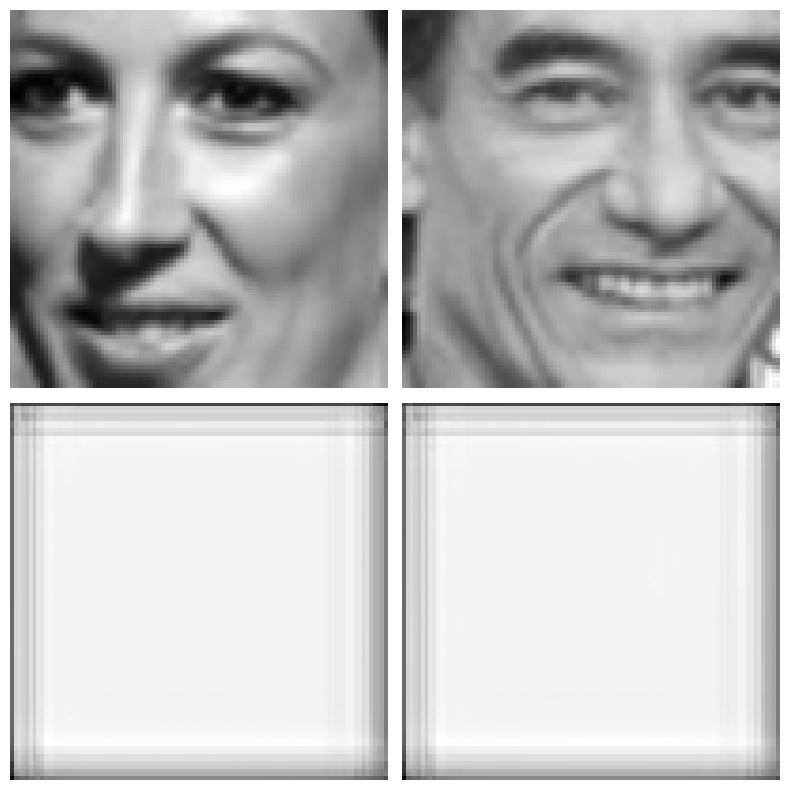

104/104 ━━━━━━━━━━━━━━━━━━━━ 135s 678ms/step - loss: 0.0847 - val_loss: 0.0853
Epoch 2/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - loss: 0.0060---
<class 'tensorflow.python.framework.ops.EagerTensor'>
<class 'tensorflow.python.framework.ops.EagerTensor'>
(4, 100, 100, 1)
(4, 100, 100, 1)
<dtype: 'float32'>
<dtype: 'float32'>
Range of four_images: [ 0.006862745154649019 , 0.9125000238418579 ]
Range of img_pred: [ 0.1343201845884323 , 0.4351482093334198 ]
---


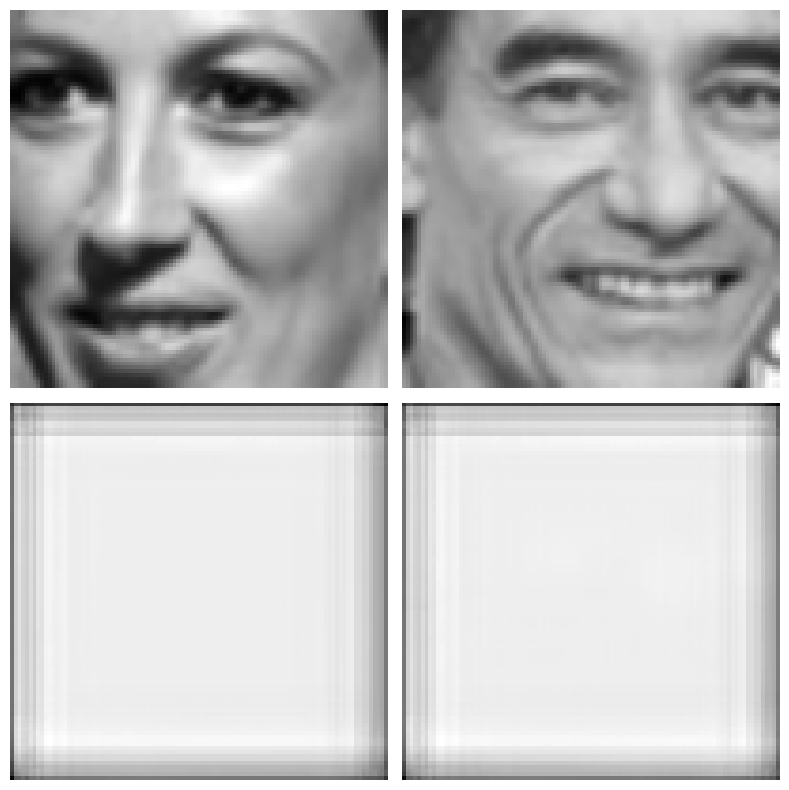

104/104 ━━━━━━━━━━━━━━━━━━━━ 22s 211ms/step - loss: 0.0059 - val_loss: 0.0613
Epoch 3/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step - loss: 0.0054---
<class 'tensorflow.python.framework.ops.EagerTensor'>
<class 'tensorflow.python.framework.ops.EagerTensor'>
(4, 100, 100, 1)
(4, 100, 100, 1)
<dtype: 'float32'>
<dtype: 'float32'>
Range of four_images: [ 0.006862745154649019 , 0.9125000238418579 ]
Range of img_pred: [ 0.13870897889137268 , 0.5159098505973816 ]
---


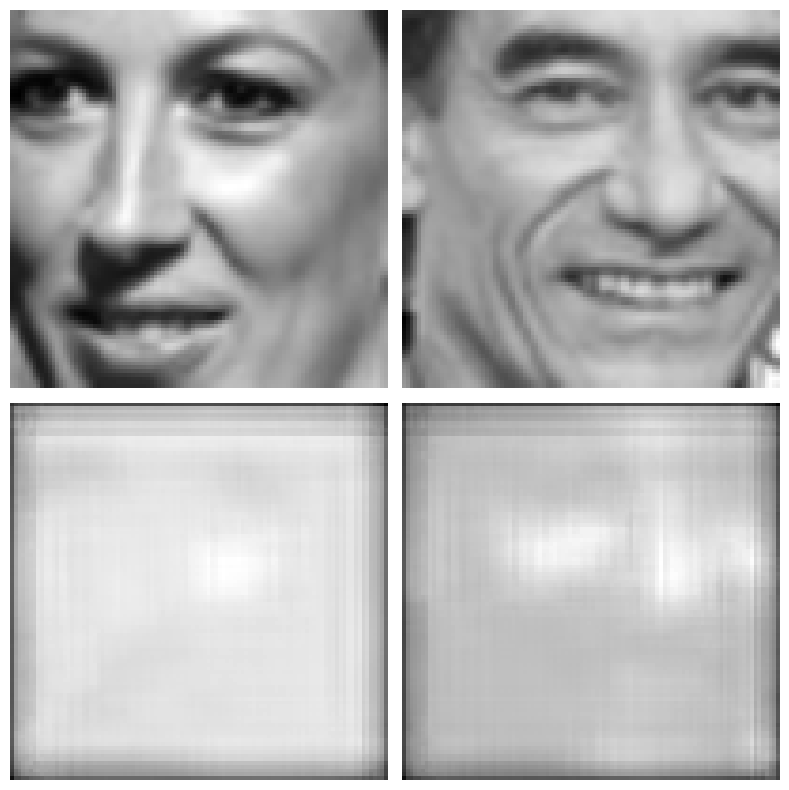

104/104 ━━━━━━━━━━━━━━━━━━━━ 22s 215ms/step - loss: 0.0054 - val_loss: 0.0436
Epoch 4/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - loss: 0.0048---
<class 'tensorflow.python.framework.ops.EagerTensor'>
<class 'tensorflow.python.framework.ops.EagerTensor'>
(4, 100, 100, 1)
(4, 100, 100, 1)
<dtype: 'float32'>
<dtype: 'float32'>
Range of four_images: [ 0.006862745154649019 , 0.9125000238418579 ]
Range of img_pred: [ 0.13722340762615204 , 0.6044440865516663 ]
---


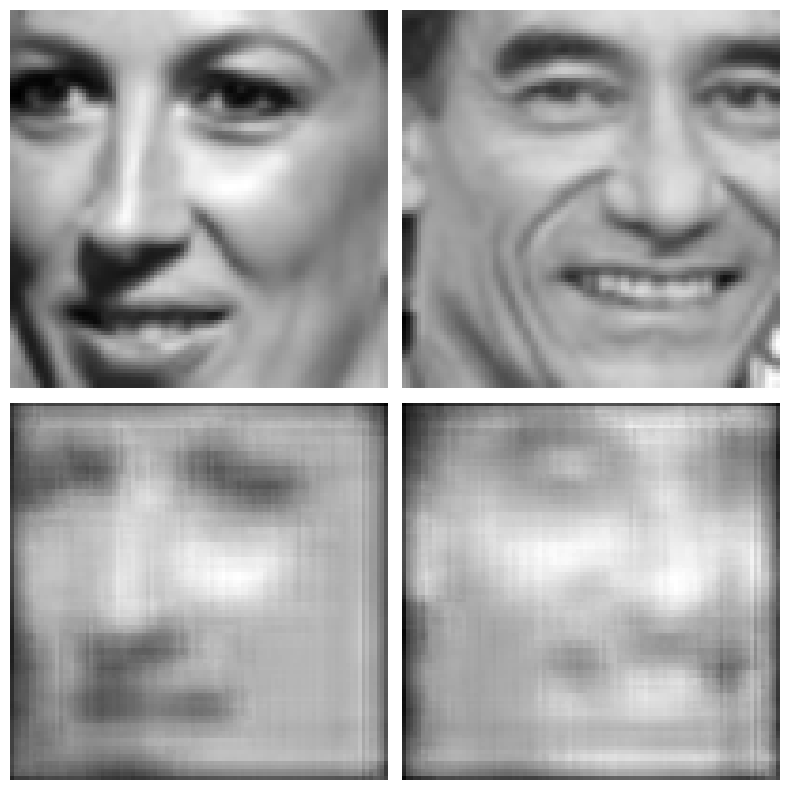

104/104 ━━━━━━━━━━━━━━━━━━━━ 23s 217ms/step - loss: 0.0048 - val_loss: 0.0302
Epoch 5/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step - loss: 0.0044---
<class 'tensorflow.python.framework.ops.EagerTensor'>
<class 'tensorflow.python.framework.ops.EagerTensor'>
(4, 100, 100, 1)
(4, 100, 100, 1)
<dtype: 'float32'>
<dtype: 'float32'>
Range of four_images: [ 0.006862745154649019 , 0.9125000238418579 ]
Range of img_pred: [ 0.07075227051973343 , 0.635101854801178 ]
---


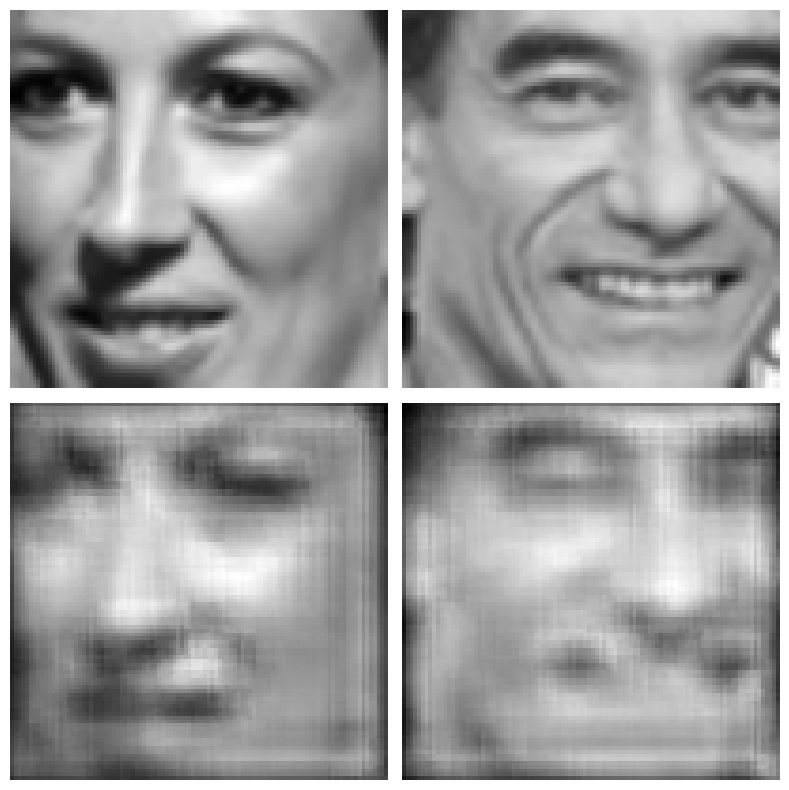

104/104 ━━━━━━━━━━━━━━━━━━━━ 23s 216ms/step - loss: 0.0044 - val_loss: 0.0224
Epoch 6/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 208ms/step - loss: 0.0041---
<class 'tensorflow.python.framework.ops.EagerTensor'>
<class 'tensorflow.python.framework.ops.EagerTensor'>
(4, 100, 100, 1)
(4, 100, 100, 1)
<dtype: 'float32'>
<dtype: 'float32'>
Range of four_images: [ 0.006862745154649019 , 0.9125000238418579 ]
Range of img_pred: [ 0.030124163255095482 , 0.7180564999580383 ]
---


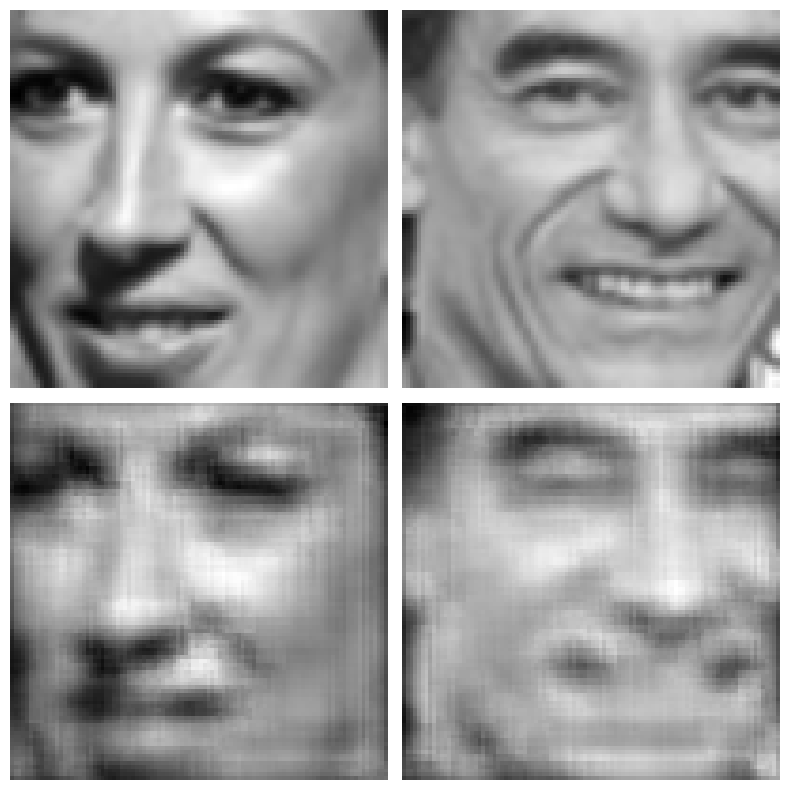

104/104 ━━━━━━━━━━━━━━━━━━━━ 23s 218ms/step - loss: 0.0040 - val_loss: 0.0134
Epoch 7/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - loss: 0.0038---
<class 'tensorflow.python.framework.ops.EagerTensor'>
<class 'tensorflow.python.framework.ops.EagerTensor'>
(4, 100, 100, 1)
(4, 100, 100, 1)
<dtype: 'float32'>
<dtype: 'float32'>
Range of four_images: [ 0.006862745154649019 , 0.9125000238418579 ]
Range of img_pred: [ -0.009562790393829346 , 0.7731127738952637 ]
---


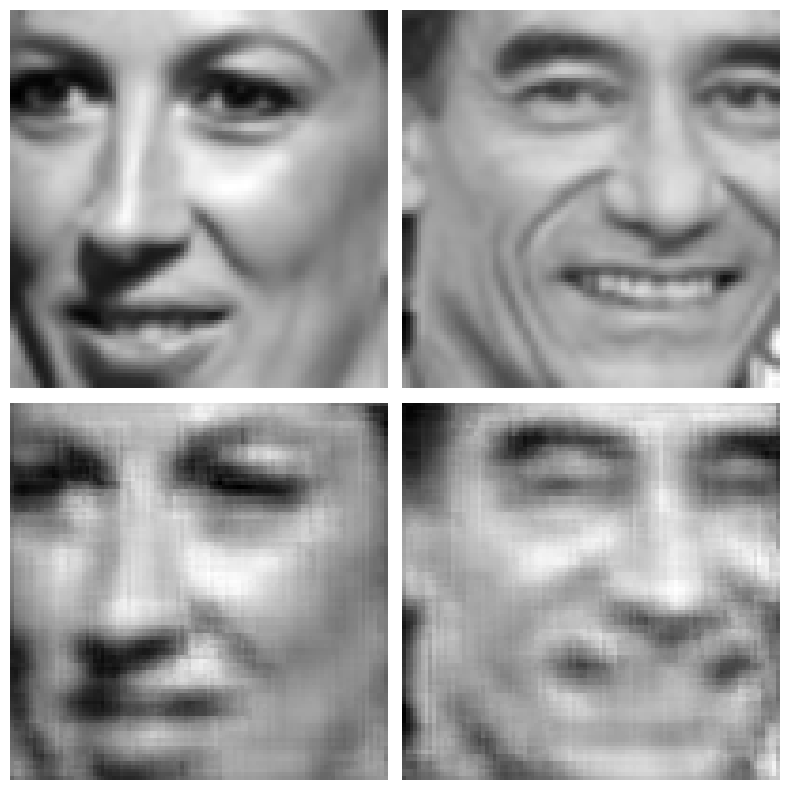

104/104 ━━━━━━━━━━━━━━━━━━━━ 23s 224ms/step - loss: 0.0038 - val_loss: 0.0075
Epoch 8/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - loss: 0.0035---
<class 'tensorflow.python.framework.ops.EagerTensor'>
<class 'tensorflow.python.framework.ops.EagerTensor'>
(4, 100, 100, 1)
(4, 100, 100, 1)
<dtype: 'float32'>
<dtype: 'float32'>
Range of four_images: [ 0.006862745154649019 , 0.9125000238418579 ]
Range of img_pred: [ -0.03814205527305603 , 0.8230874538421631 ]
---


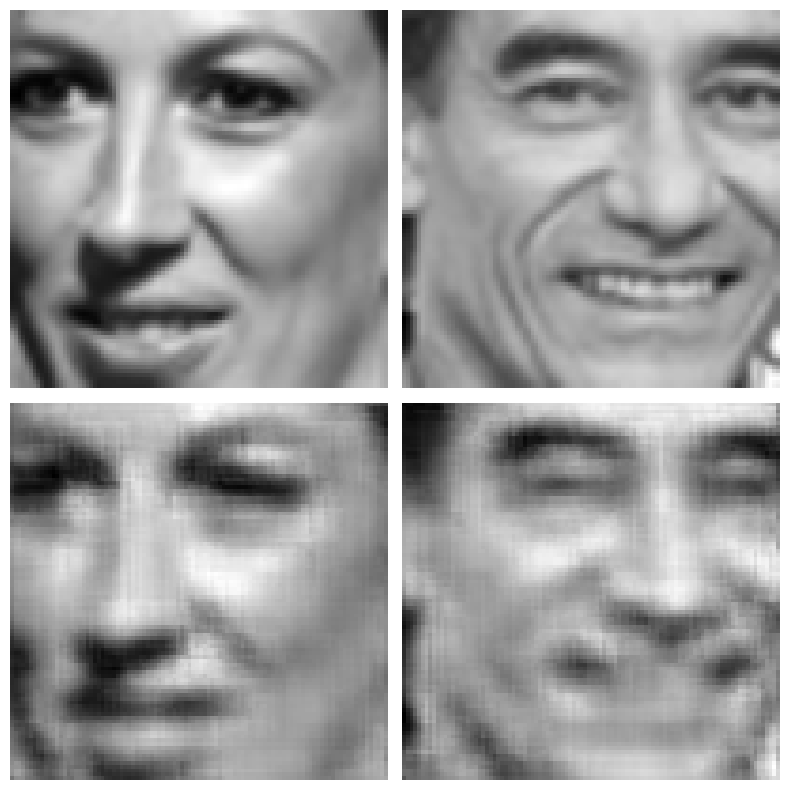

104/104 ━━━━━━━━━━━━━━━━━━━━ 23s 224ms/step - loss: 0.0035 - val_loss: 0.0046
Epoch 9/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step - loss: 0.0033---
<class 'tensorflow.python.framework.ops.EagerTensor'>
<class 'tensorflow.python.framework.ops.EagerTensor'>
(4, 100, 100, 1)
(4, 100, 100, 1)
<dtype: 'float32'>
<dtype: 'float32'>
Range of four_images: [ 0.006862745154649019 , 0.9125000238418579 ]
Range of img_pred: [ -0.04525579884648323 , 0.8579251170158386 ]
---


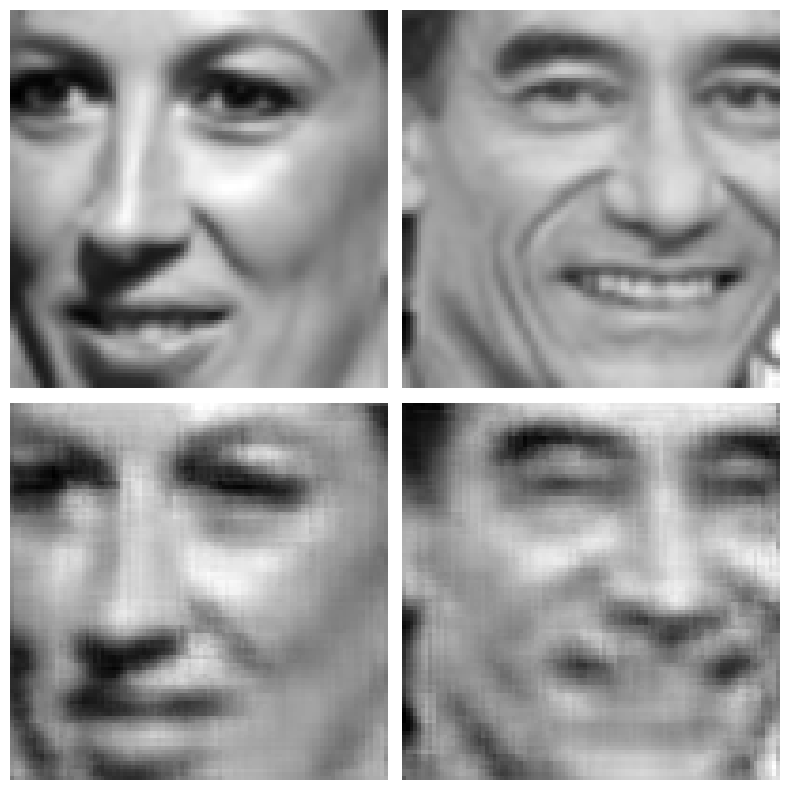

104/104 ━━━━━━━━━━━━━━━━━━━━ 23s 222ms/step - loss: 0.0033 - val_loss: 0.0032
Epoch 10/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - loss: 0.0030---
<class 'tensorflow.python.framework.ops.EagerTensor'>
<class 'tensorflow.python.framework.ops.EagerTensor'>
(4, 100, 100, 1)
(4, 100, 100, 1)
<dtype: 'float32'>
<dtype: 'float32'>
Range of four_images: [ 0.006862745154649019 , 0.9125000238418579 ]
Range of img_pred: [ -0.04377530515193939 , 0.8683203458786011 ]
---


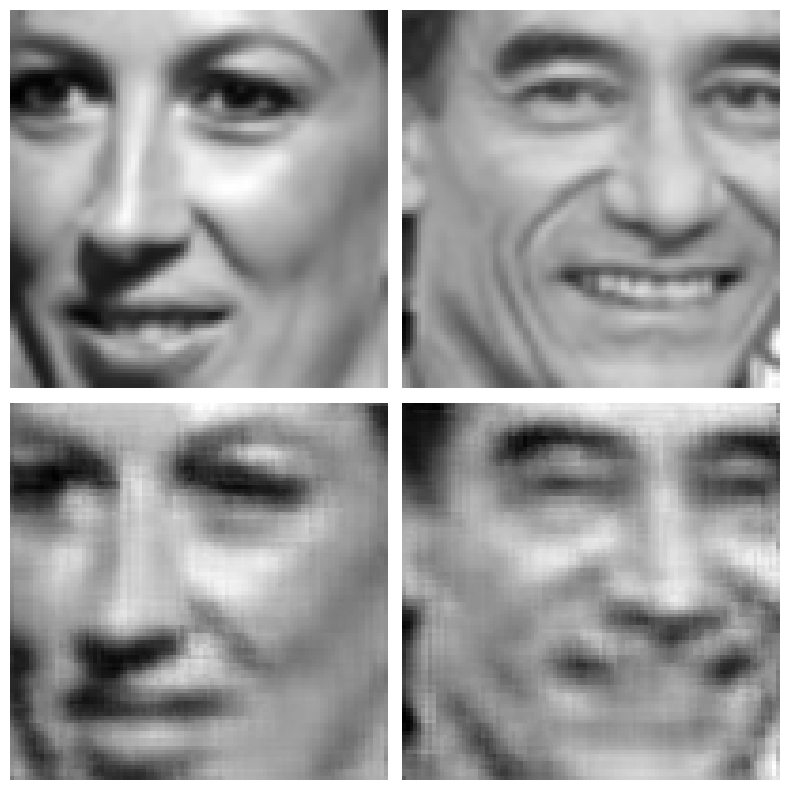

104/104 ━━━━━━━━━━━━━━━━━━━━ 23s 221ms/step - loss: 0.0030 - val_loss: 0.0026
Epoch 11/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - loss: 0.0027---
<class 'tensorflow.python.framework.ops.EagerTensor'>
<class 'tensorflow.python.framework.ops.EagerTensor'>
(4, 100, 100, 1)
(4, 100, 100, 1)
<dtype: 'float32'>
<dtype: 'float32'>
Range of four_images: [ 0.006862745154649019 , 0.9125000238418579 ]
Range of img_pred: [ -0.047184497117996216 , 0.8763056397438049 ]
---


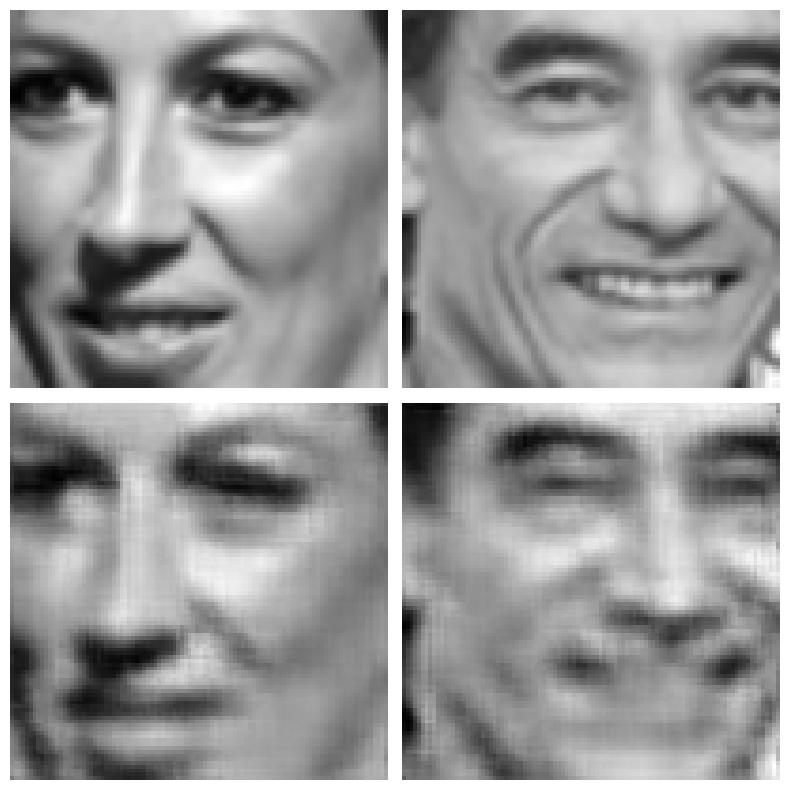

104/104 ━━━━━━━━━━━━━━━━━━━━ 23s 221ms/step - loss: 0.0027 - val_loss: 0.0023
Epoch 12/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step - loss: 0.0025---
<class 'tensorflow.python.framework.ops.EagerTensor'>
<class 'tensorflow.python.framework.ops.EagerTensor'>
(4, 100, 100, 1)
(4, 100, 100, 1)
<dtype: 'float32'>
<dtype: 'float32'>
Range of four_images: [ 0.006862745154649019 , 0.9125000238418579 ]
Range of img_pred: [ -0.04457680881023407 , 0.8855917453765869 ]
---


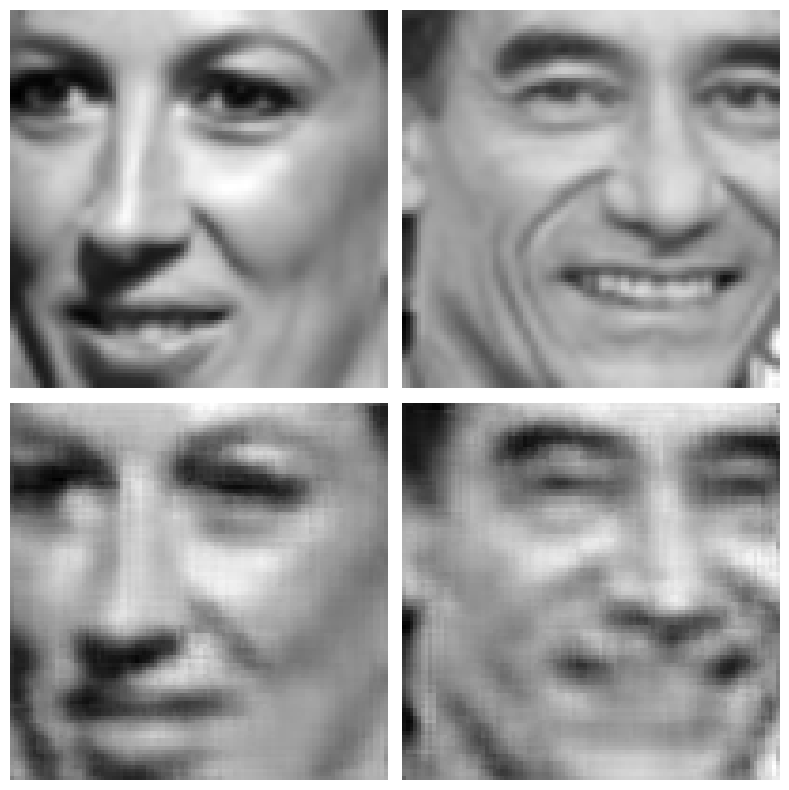

104/104 ━━━━━━━━━━━━━━━━━━━━ 23s 221ms/step - loss: 0.0024 - val_loss: 0.0021
Epoch 13/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step - loss: 0.0023---
<class 'tensorflow.python.framework.ops.EagerTensor'>
<class 'tensorflow.python.framework.ops.EagerTensor'>
(4, 100, 100, 1)
(4, 100, 100, 1)
<dtype: 'float32'>
<dtype: 'float32'>
Range of four_images: [ 0.006862745154649019 , 0.9125000238418579 ]
Range of img_pred: [ -0.040834031999111176 , 0.8869984149932861 ]
---


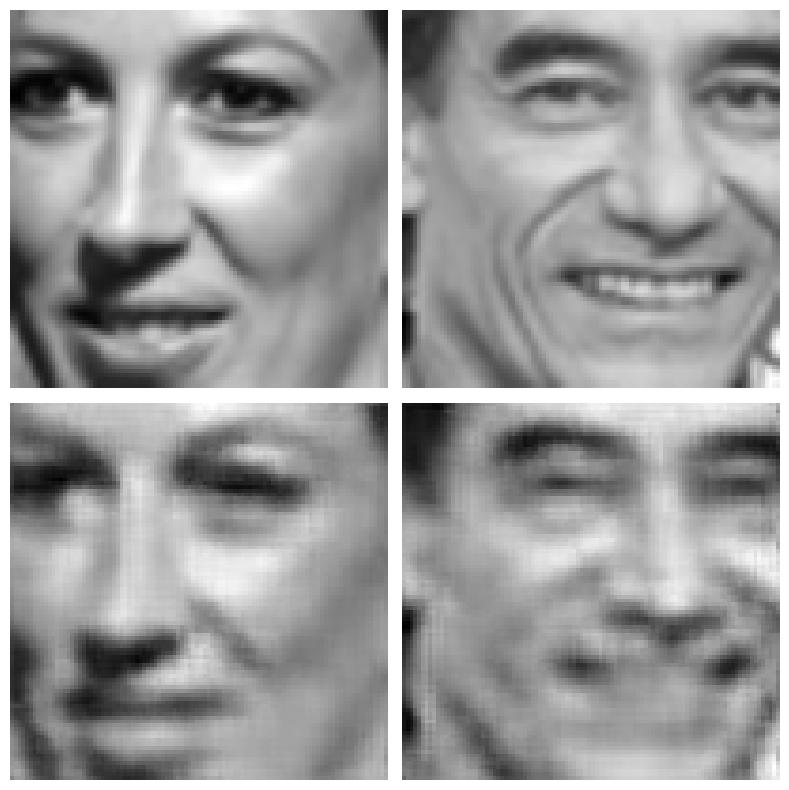

104/104 ━━━━━━━━━━━━━━━━━━━━ 23s 221ms/step - loss: 0.0023 - val_loss: 0.0020
Epoch 14/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - loss: 0.0022---
<class 'tensorflow.python.framework.ops.EagerTensor'>
<class 'tensorflow.python.framework.ops.EagerTensor'>
(4, 100, 100, 1)
(4, 100, 100, 1)
<dtype: 'float32'>
<dtype: 'float32'>
Range of four_images: [ 0.006862745154649019 , 0.9125000238418579 ]
Range of img_pred: [ -0.03318353369832039 , 0.8874825239181519 ]
---


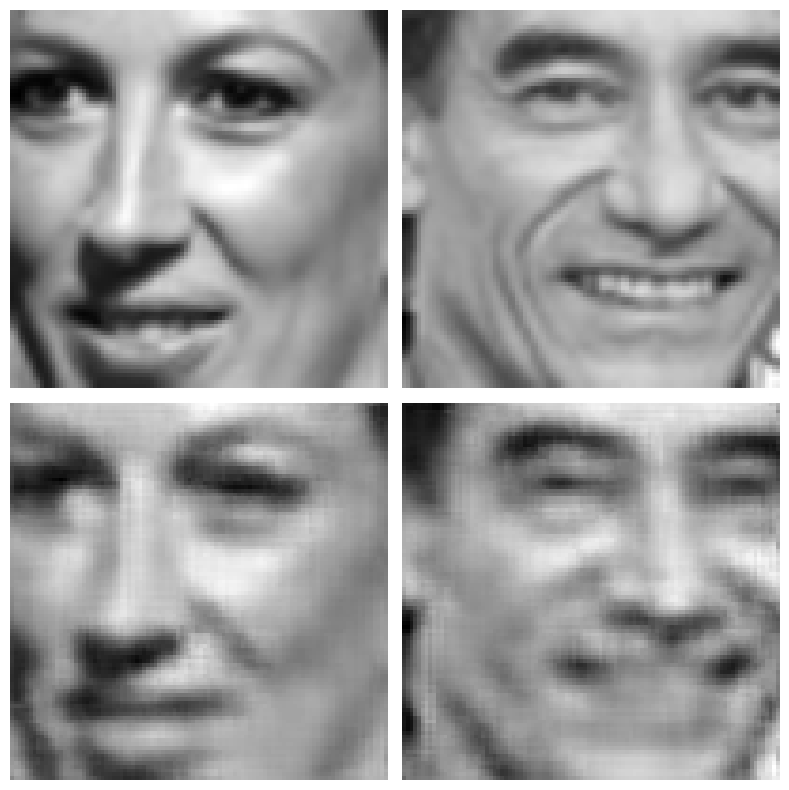

104/104 ━━━━━━━━━━━━━━━━━━━━ 23s 222ms/step - loss: 0.0022 - val_loss: 0.0019
Epoch 15/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - loss: 0.0021---
<class 'tensorflow.python.framework.ops.EagerTensor'>
<class 'tensorflow.python.framework.ops.EagerTensor'>
(4, 100, 100, 1)
(4, 100, 100, 1)
<dtype: 'float32'>
<dtype: 'float32'>
Range of four_images: [ 0.006862745154649019 , 0.9125000238418579 ]
Range of img_pred: [ -0.03321540355682373 , 0.891152560710907 ]
---


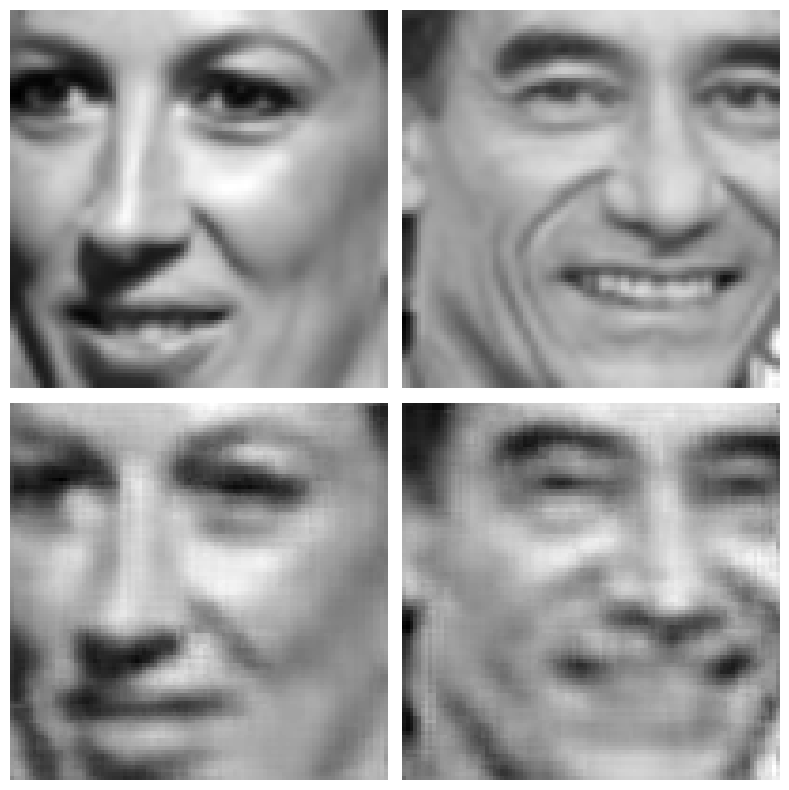

104/104 ━━━━━━━━━━━━━━━━━━━━ 23s 223ms/step - loss: 0.0021 - val_loss: 0.0018
Epoch 16/25
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - loss: 0.0020---
<class 'tensorflow.python.framework.ops.EagerTensor'>
<class 'tensorflow.python.framework.ops.EagerTensor'>
(4, 100, 100, 1)
(4, 100, 100, 1)
<dtype: 'float32'>
<dtype: 'float32'>
Range of four_images: [ 0.006862745154649019 , 0.9125000238418579 ]
Range of img_pred: [ -0.02966071292757988 , 0.8943848609924316 ]
---


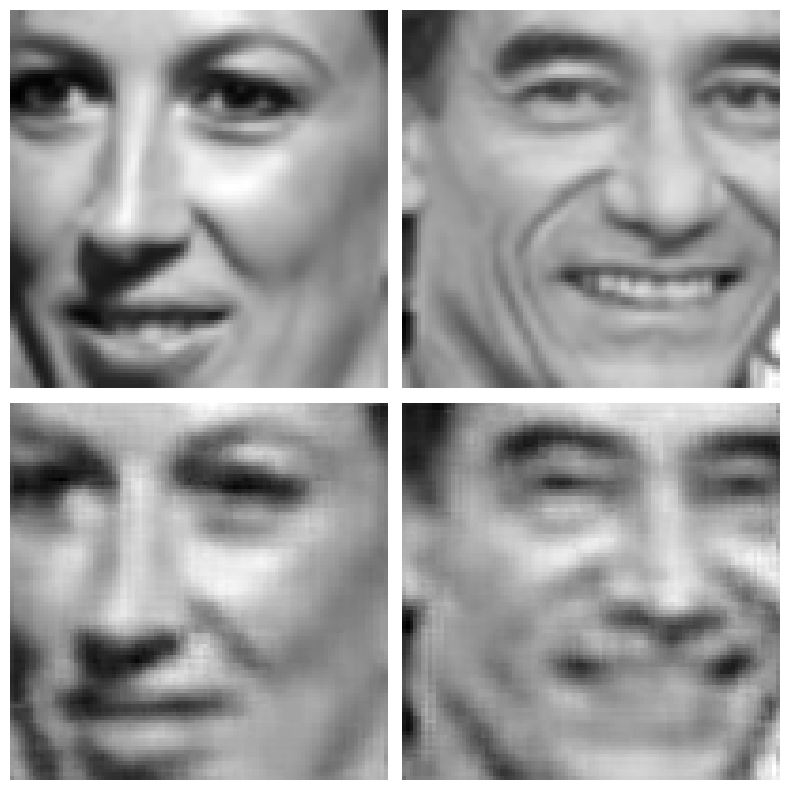

104/104 ━━━━━━━━━━━━━━━━━━━━ 24s 227ms/step - loss: 0.0020 - val_loss: 0.0018
Epoch 17/25
  3/104 ━━━━━━━━━━━━━━━━━━━━ 21s 212ms/step - loss: 0.0025

KeyboardInterrupt: 

In [ ]:
autoencoder_densenet.fit(train_dataset_ae,
                         epochs=25,
                         validation_data=test_dataset_ae,
                         callbacks=[reconstruction_callback])

**Final Reconstruction Results**

---
<class 'tensorflow.python.framework.ops.EagerTensor'>
<class 'tensorflow.python.framework.ops.EagerTensor'>
(16, 100, 100, 1)
(16, 100, 100, 1)
<dtype: 'float32'>
<dtype: 'float32'>
Range of four_images: [ 0.0049019609577953815 , 0.9808823466300964 ]
Range of img_pred: [ -0.017386969178915024 , 1.013231873512268 ]
---


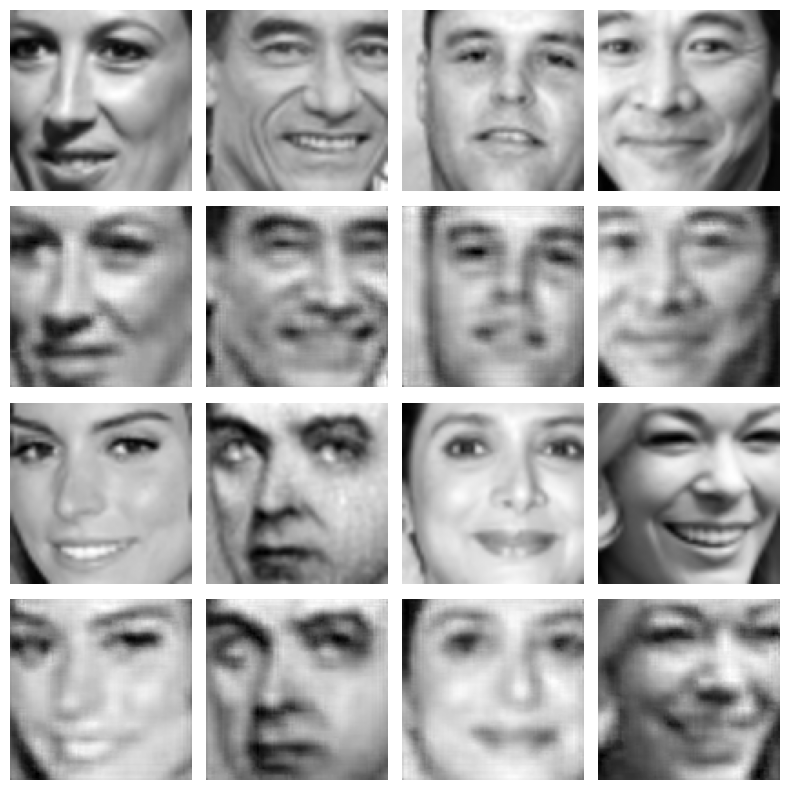

In [ ]:
from keras.callbacks import LambdaCallback
import sys
import matplotlib.pyplot as plt

rows = 4   # total rows
cols = 4   # images per row

fig, axes = plt.subplots(rows, cols, figsize=(8, 8))
images = []

# Retriving [rows] times [cols] images from the validation set
for x_batch in test_dataset_ae:
    for img in x_batch:
        images.append(img)
        if len(images) == rows*cols:
            break
    if len(images) == rows*cols:
        break
four_images = tf.stack(images)

# Image reconstruction prediction made by the Autoencoder
img_pred = autoencoder_densenet(four_images, training=False)


# Displaying the reconstruction results
#
# Row 0: the original images
# Row 1: the respective reconstructed images
for row in range(rows):
    for col in range(cols):
        base_idx = (row // 2) * cols
        idx = base_idx + col

        if row % 2 == 0:
            # Original image
            img = four_images[idx]
        else:
            # Corresponding reconstruction
            img = img_pred[idx]

        axes[row, col].imshow(img, cmap="gray")

        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## Encoder Fine-tuning

### Age Predictor Model

Model trained on top of the frozen encoder, in order to carry out the downstream age-prediction task.

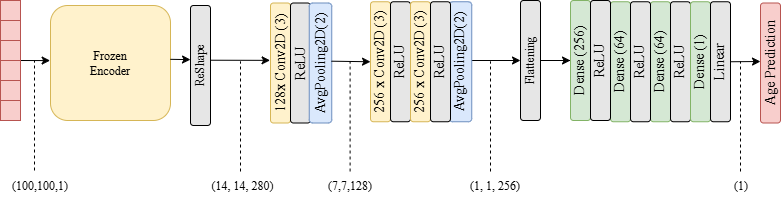

In [ ]:
input_shape=(100, 100, 1)

# The inputs of this network is compliant with the output shape of the encoder
inputs = layers.Input(shape=(out_densnet.shape[-1], ), name="Inputs")
x = layers.Reshape((out_last_block.shape[-3], out_last_block.shape[-2], out_last_block.shape[-1]))(inputs)

# Convolutional section of the network

# ConvBlock1
filters = 128
x = keras.layers.Conv2D(filters, 1, padding="same", activation="linear")(x)
x = keras.layers.ReLU()(x)
x = keras.layers.AveragePooling2D(2, strides=2)(x) # dimezza la dimensione spaziale tra un dense layer ed il successivo.

# ConvBlock2
filters = 256
x = keras.layers.Conv2D(filters, 3, padding="same", activation="linear")(x)
x = keras.layers.ReLU()(x)
x = keras.layers.Conv2D(filters, 3, padding="same", activation="linear")(x)
x = keras.layers.ReLU()(x)
x = keras.layers.AveragePooling2D(7)(x)

# Fully connected section of the network
x = layers.Flatten()(x)
x = layers.Dense(256, activation="relu", kernel_regularizer=regularizers.L1(0.001))(x)
x = layers.Dense(64, activation="relu", kernel_regularizer=regularizers.L1(0.001))(x)
x = layers.Dense(64, activation="relu", kernel_regularizer=regularizers.L1(0.001))(x)
x = layers.Dropout(0.1)(x)
out_age_predictor = layers.Dense(1, activation="linear")(x)

# Model defintion
age_predictor = keras.Model(inputs, out_age_predictor, name="age_predictor")
age_predictor.summary()

Model: "age_predictor"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Inputs (InputLayer)             │ (None, 54880)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_3 (Reshape)             │ (None, 14, 14, 280)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 14, 14, 128)    │        35,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_44 (ReLU)                 │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_4             │ (None, 7, 7, 128)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 7, 7, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_45 (ReLU)                 │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 7, 7, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_46 (ReLU)                 │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_5             │ (None, 1, 1, 256)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,007,681 (3.84 MB)

 Trainable params: 1,007,681 (3.84 MB)

 Non-trainable params: 0 (0.00 B)

### Age Predictor Training

**Fine Tuned model Definition**

In [ ]:
# Freezing the encoder
encoder.trainable = False
inputs = layers.Input(shape=(100, 100, 1, ), name="Inputs")

# First the input is parsed by the encoder
x = encoder(inputs, training=False)

# Then the age predictor works on the latent representation produced by the encoder
x = age_predictor(x)

# Model definition
net_2 = keras.Model(inputs, x, name="net")
net_2.summary()

Model: "net"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Inputs (InputLayer)             │ (None, 100, 100, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 54880)          │       353,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ age_predictor (Functional)      │ (None, 1)              │     1,007,681 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,360,777 (5.19 MB)

 Trainable params: 1,007,681 (3.84 MB)

 Non-trainable params: 353,096 (1.35 MB)

**Downstream task fine-tuning**

In [ ]:
net_2.compile(
    loss=keras.losses.MeanAbsoluteError(),
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    metrics=[
        keras.metrics.MeanAbsoluteError(),
        keras.metrics.MeanSquaredError(),
        keras.metrics.RootMeanSquaredError()
    ]
)

callback = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

history = net_2.fit(
    train_dataset_fn,
    validation_data = val_dataset_fn,
    epochs=40,
    callbacks=[earlyStop, reduce_lr]
)

Epoch 1/40
     37/Unknown 21s 238ms/step - loss: 4.8908 - mean_absolute_error: 0.3075 - mean_squared_error: 0.1602 - root_mean_squared_error: 0.3899

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:160: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


37/37 ━━━━━━━━━━━━━━━━━━━━ 35s 620ms/step - loss: 4.8764 - mean_absolute_error: 0.3058 - mean_squared_error: 0.1586 - root_mean_squared_error: 0.3879 - val_loss: 3.2570 - val_mean_absolute_error: 0.2021 - val_mean_squared_error: 0.0667 - val_root_mean_squared_error: 0.2582 - learning_rate: 0.0010
Epoch 2/40
37/37 ━━━━━━━━━━━━━━━━━━━━ 5s 126ms/step - loss: 2.8443 - mean_absolute_error: 0.2048 - mean_squared_error: 0.0658 - root_mean_squared_error: 0.2565 - val_loss: 1.7578 - val_mean_absolute_error: 0.1898 - val_mean_squared_error: 0.0576 - val_root_mean_squared_error: 0.2400 - learning_rate: 0.0010
Epoch 3/40
37/37 ━━━━━━━━━━━━━━━━━━━━ 5s 125ms/step - loss: 1.5209 - mean_absolute_error: 0.1941 - mean_squared_error: 0.0600 - root_mean_squared_error: 0.2449 - val_loss: 0.9911 - val_mean_absolute_error: 0.1881 - val_mean_squared_error: 0.0579 - val_root_mean_squared_error: 0.2406 - learning_rate: 0.0010
Epoch 4/40
37/37 ━━━━━━━━━━━━━━━━━━━━ 5s 129ms/step - loss: 0.9038 - mean_absolute_err

### Fine-tuning results

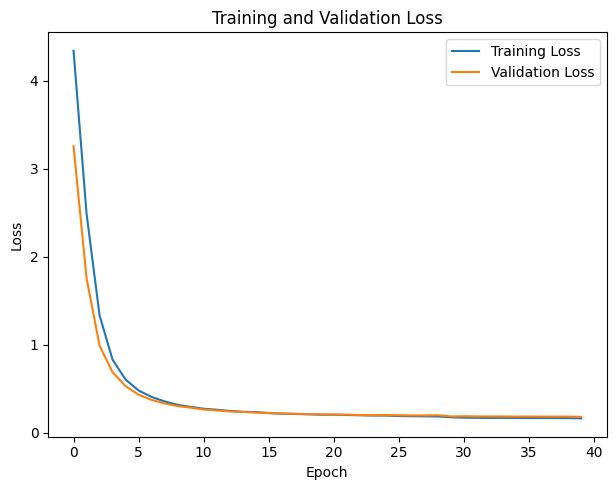

In [ ]:
# Learning curves

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()



plt.tight_layout()
plt.show()

**Saving the model and its weight**

In [ ]:
# net_2.save("net_2.h5")

In [ ]:
# net_2.save_weights("net_2_weights.weights.h5")

**Age Predictions**

In [ ]:
y_pred_norm = net_2.predict(X_test_norm)

29/29 ━━━━━━━━━━━━━━━━━━━━ 55s 861ms/step


**Unscaling the age prediction**

In [ ]:
y_pred = minmax_unscale(y_pred_norm,age_min,age_max )

**Analyzing the distribution of the predictions**

In [ ]:
y_pred

array([[32.33304858],
       [36.9555583 ],
       [47.71886039],
       [41.83679336],
       [25.80806777],
       [60.70514798],
       [33.63077193],
       [45.53699672],
       [32.5613448 ],
       [33.75472343],
       [28.51745127],
       [29.71300785],
       [47.3006103 ],
       [31.40910617],
       [25.41427559],
       [33.6937511 ],
       [25.89476588],
       [26.88785315],
       [27.25840475],
       [32.05172437],
       [28.88522728],
       [44.08526611],
       [40.64000779],
       [29.68884294],
       [40.79848504],
       [36.99884513],
       [45.21846062],
       [29.44901653],
       [38.22020268],
       [30.31085096],
       [33.81693512],
       [32.83414388],
       [26.80734923],
       [26.7572563 ],
       [36.6415233 ],
       [32.54749924],
       [37.48245198],
       [43.60829943],
       [30.45763208],
       [47.32592124],
       [31.73292769],
       [30.62852107],
       [29.25535366],
       [27.59753288],
       [40.1239624 ],
       [32

In [ ]:
y_test

memmap([ 39.,  52.,  39.,  46.,  26., 100.,  44.,  27.,  18.,  44.,  25.,
         20.,  48.,  24.,  18.,  32.,  37.,  26.,  15.,  45.,  32.,  42.,
         30.,  21.,  43.,  31.,  59.,  55.,  44.,  32.,  20.,  28.,  34.,
         21.,  60.,  28.,  28.,  31.,  37.,  78.,  23.,  37.,  27.,  41.,
         51.,  35.,  33.,  36.,  20.,  76.,  30.,  29.,  33.,  45.,  34.,
         27.,  43.,  47.,  53.,  49.,  22.,  35.,  39.,  36.,  34.,  31.,
         26.,  28.,  32.,  28.,  82.,  20.,  24.,  24.,  69.,  29.,  30.,
         29.,  23.,  24.,  18.,  23.,  32.,  46.,  26.,  66.,  20.,  28.,
         28.,  41.,  36.,  26.,  25.,  40.,  22.,  26.,  21.,  32.,  54.,
         48.,  30.,  40.,  27.,  35.,  30.,  30.,  21.,  33.,  21.,  25.,
         44.,  38.,  45.,  40.,  26.,  32.,  31.,  31.,  30.,  22.,  49.,
         17.,  30.,  32.,  44.,  33.,  24.,  22.,  19.,  40.,  56.,  33.,
         45.,  19.,  46.,  50.,  27.,  51.,  58.,  47.,  33.,  55.,  24.,
         59.,  18.,  29.,  61.,  60., 

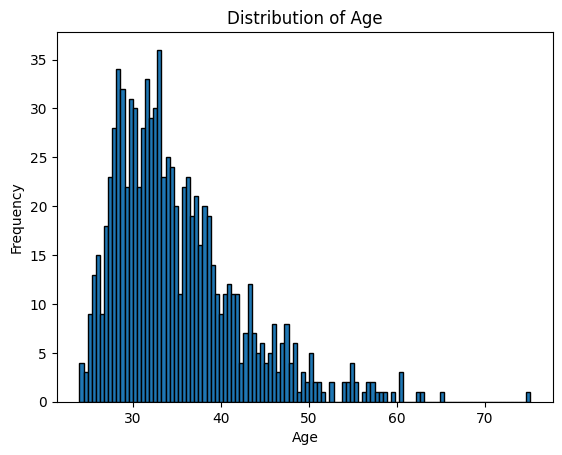

In [ ]:
# Age predictions distribution

plt.hist(y_pred, bins=110, edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Distribution of Age')
plt.show()

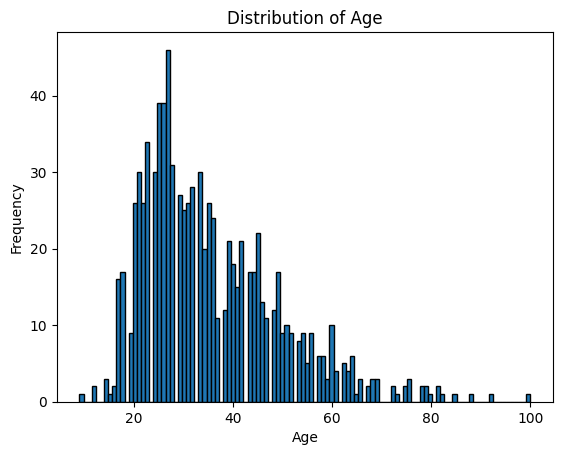

In [ ]:
# Age test distribution

plt.hist(y_test, bins=110, edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Distribution of Age')
plt.show()

**Further statistics analysis**

In [ ]:
np.mean(y_pred)

np.float64(34.95702089558045)

In [ ]:
np.std(y_pred)

np.float64(7.202470769171719)

In [ ]:
np.std(y_test)

np.float64(13.826021048179097)

In [ ]:
np.mean(y_test)

np.float64(35.49444444444445)

**Age Predictor Evaluation Metrics**

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Test MAE (anni):", mae)
print("Test RMSE (anni):", rmse)
print("Test R2:", r2)

Test MAE (anni): 10.038441444271141
Test RMSE (anni): 13.10179520709616
Test R2: 0.10201892068995566


**Plotting predictions**

In [ ]:
# Sampling a test image
random_index = np.random.randint(0, len(X_test))

# Plotting the current image, along side with its true and predicted age label
plt.imshow(X_test[random_index], cmap="gray")
plt.title(f'Predicted Age: {y_pred[random_index][0]:.0f}, True Age: {y_test[random_index]:.0f}')
plt.axis('off')
plt.show()

# Ensembling

## Loading the models

The previously seen models, once trained, has been saved and uploaded in a publicly available GDrive folder.

We retrive them in order to implement the ensemble model.

In [ ]:
import zipfile
import numpy as np
import os
from tensorflow.keras.models import load_model

output_dir = "/downloadedModels/"

# Function used to dowload all the Numpy arrays stored in the linked GDrive folder
def download_gdrive_folder():

    # DO NOT MODIFY THIS LINK
    folder_url = "https://drive.google.com/drive/folders/15182Kbzszn0ccX1W3kycflF2kZdpudlS?usp=drive_link"

    # Dowloading only if it is necessary
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)

        # Download the entire folder
        !gdown --folder "{folder_url}" -O "{output_dir}"

        print("Folder downloaded successfully!")
    else:
        print("Folder already downloaded.")

# Funciton that loads a Numpy array from a zip file
def load_model_from_zip(filename):
  filename = output_dir + "EnsembleModel/" + filename
  # Load the numpy array
  model = load_model(filename)
  print(f'Loaded {filename}')

  return model


# Dowloading all the zipped Numpy files
download_gdrive_folder()

model_transfer = load_model_from_zip('model_transfer.h5')
model_ssl = load_model_from_zip('model_ssl.h5')
model_mtl = load_model_from_zip('model_mtl.h5')

Folder already downloaded.


Loaded /downloadedModels/EnsembleModel/model_transfer.h5


Loaded /downloadedModels/EnsembleModel/model_ssl.h5


Loaded /downloadedModels/EnsembleModel/model_mtl.h5


## Ensemble model assessment (on our Test set)

### Data Preparation

In [ ]:
#Min-Max scaling parameters
age_min = y_train_aug.min()
age_max = y_train_aug.max()

#Min-Max scaling functions
def minmax_scale(y, min_val, max_val):
    return (y - min_val) / (max_val - min_val)

def minmax_unscale(y_norm, min_val, max_val):
    return y_norm * (max_val - min_val) + min_val

# Applying Min-max age scaling to the training set
y_train_norm = minmax_scale(y_train_aug, age_min, age_max)
y_test_norm = minmax_scale(y_test, age_min, age_max)

# Scaling the images
X_test_norm_ssl = np.memmap("X_test_norm.npy", dtype="float32", mode="w+", shape=X_test.shape)
X_test_norm_ssl[:] = (X_test.astype("float32") / 255.0)
X_test_norm_ssl.flush()

### Models invidual predictions

#### Target Age Distribution  

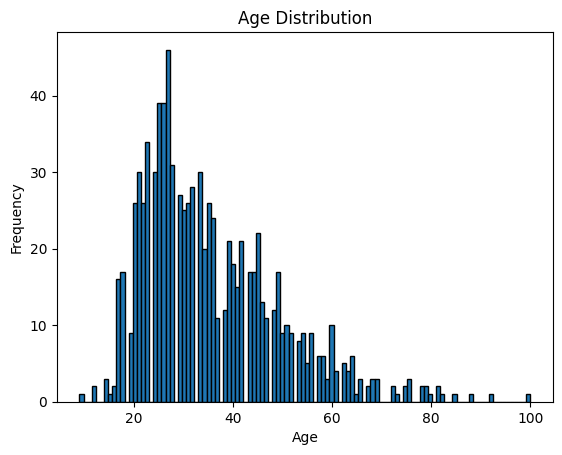

In [ ]:
# Age distribution in our test set

plt.hist(y_test, bins=110, edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')
plt.show()

We retrive the prediction on our test set from each individual model developed within this notebook.

#### Transfer Learning

In [ ]:
# Transfer learning model age predictions
y_pred_norm_transfer = model_transfer.predict(X_test)

# Unnormalized age predictions
y_pred_transfer = minmax_unscale(y_pred_norm_transfer, age_min, age_max)

29/29 ━━━━━━━━━━━━━━━━━━━━ 29s 481ms/step


In [ ]:
# Displaying the age predictions
y_pred_transfer

array([[38.34348783],
       [48.81275061],
       [34.18889591],
       [44.5816088 ],
       [27.69618641],
       [41.89303383],
       [30.9575671 ],
       [48.90177965],
       [31.00381231],
       [35.59137884],
       [36.50022337],
       [35.43634224],
       [44.99829543],
       [45.85403419],
       [26.96970402],
       [45.85512057],
       [51.71378756],
       [37.13630253],
       [30.38403021],
       [42.92089576],
       [38.11231619],
       [43.95831475],
       [42.96350068],
       [38.2787663 ],
       [48.7260862 ],
       [41.29629785],
       [52.4948225 ],
       [58.13848656],
       [34.48166215],
       [33.96330398],
       [27.28526747],
       [46.54865623],
       [31.20814975],
       [30.55336481],
       [63.85385197],
       [29.89622951],
       [38.56034201],
       [47.33912638],
       [36.68516794],
       [50.10393751],
       [22.78004315],
       [19.32692994],
       [35.51544863],
       [33.73594895],
       [47.21679798],
       [23

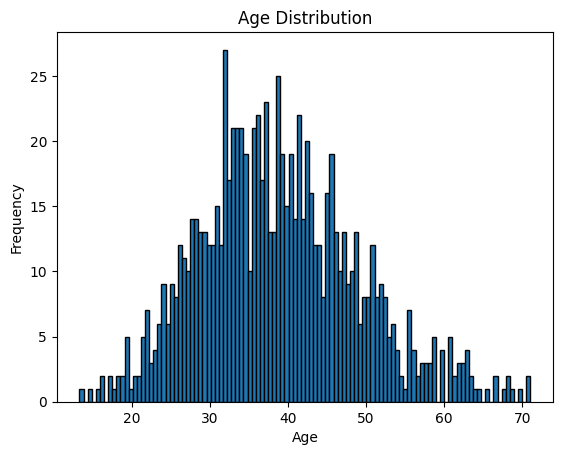

In [ ]:
# Plotting the age predictions
plt.hist(y_pred_transfer, bins=110, edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')
plt.show()

#### SSL

In [ ]:
# Self supervised age predictions
y_pred_norm_ssl = model_ssl.predict(X_test_norm_ssl)

# Unnormalized age predictions
y_pred_ssl = minmax_unscale(y_pred_norm_ssl, age_min, age_max)

29/29 ━━━━━━━━━━━━━━━━━━━━ 12s 223ms/step


In [ ]:
# Displaying the age predictions
y_pred_ssl

array([[32.33304858],
       [36.9555583 ],
       [47.71886039],
       [41.83679855],
       [25.80806777],
       [60.70515317],
       [33.63077193],
       [45.53700191],
       [32.5613448 ],
       [33.75472343],
       [28.51745127],
       [29.71300785],
       [47.3006103 ],
       [31.40910617],
       [25.41427559],
       [33.6937511 ],
       [25.89476588],
       [26.88785315],
       [27.25840475],
       [32.05172437],
       [28.88522728],
       [44.08526611],
       [40.64000779],
       [29.68884294],
       [40.79848504],
       [36.99884254],
       [45.21846062],
       [29.44901523],
       [38.22020268],
       [30.31085226],
       [33.81693512],
       [32.83414388],
       [26.80734794],
       [26.7572563 ],
       [36.6415233 ],
       [32.54749924],
       [37.48245198],
       [43.60829943],
       [30.45763208],
       [47.32592124],
       [31.73292899],
       [30.62852107],
       [29.25535366],
       [27.59753418],
       [40.1239624 ],
       [32

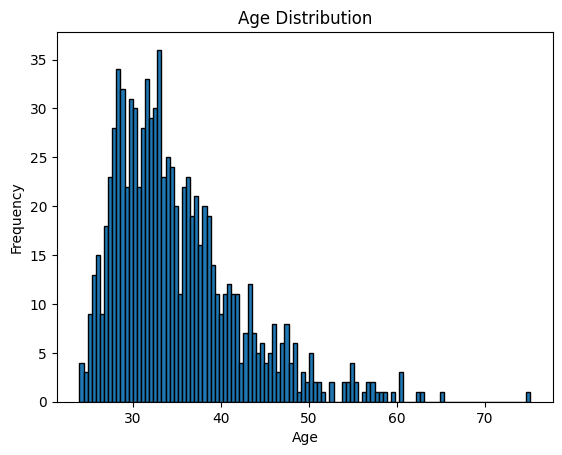

In [ ]:
# Plotting the age predictions
plt.hist(y_pred_ssl, bins=110, edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')
plt.show()

#### Multi-task

In [ ]:
# Multitasking model age predictions
y_pred_norm_mtl = model_mtl.predict(X_test_norm_ssl)[0].flatten()

# Unnormalized age predictions
y_pred_mtl = minmax_unscale(y_pred_norm_mtl, age_min, age_max)

29/29 ━━━━━━━━━━━━━━━━━━━━ 4s 68ms/step


In [ ]:
# Displaying age predictions
y_pred_mtl

array([35.10048103, 54.51031125, 47.69568852, 33.73057407, 27.55160917,
       45.08051318, 30.98988767, 31.67597161, 32.79546446, 46.67102352,
       37.38970485, 25.40632087, 50.95674381, 28.64327218, 33.26672438,
       38.26563117, 30.60286011, 28.20704879, 30.31387417, 38.39818558,
       31.87453228, 41.87321964, 30.62745932, 28.00952913, 45.58814493,
       28.73685677, 47.58901027, 30.04951467, 36.78907189, 27.73585109,
       31.87830999, 47.52969214, 26.07289009, 25.40637143, 46.58867353,
       54.30895942, 38.96975064, 35.8236939 , 32.01767051, 38.51573285,
       47.35167813, 26.81894295, 29.55149314, 32.86300176, 39.66604763,
       26.25303797, 32.96818137, 33.52864146, 27.53089139, 74.0976395 ,
       30.01642533, 41.79678902, 53.99933219, 40.08822063, 45.42437837,
       30.55923232, 35.69755927, 36.25048208, 32.13692904, 35.66941959,
       26.32073215, 37.03401908, 41.6156818 , 29.6741599 , 25.47636153,
       26.81930594, 44.01265728, 39.0340625 , 49.01688191, 27.57

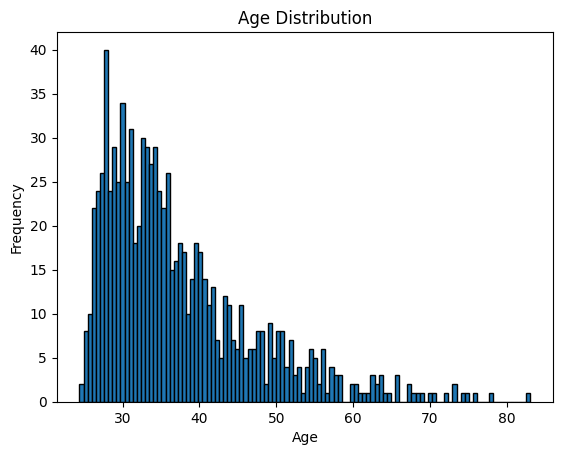

In [ ]:
# Plotting age predictions
plt.hist(y_pred_mtl, bins=110, edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')
plt.show()

### Error Correlation

In order to legitimate the implementation of an ensemble model, we study the correlation between the errors made by the individual networks

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

# Uniforming the age numpy array shape
y_test = np.ravel(y_test)
y_pred_ssl = np.ravel(y_pred_ssl)
y_pred_transfer = np.ravel(y_pred_transfer)
y_pred_mtl = np.ravel(y_pred_mtl)

# Calculating residuals for the three different model age predictions
res_ssl = y_pred_ssl - y_test
res_transfer = y_pred_transfer - y_test
res_mtl = y_pred_mtl - y_test

# Correlation matrix over the residual errors.
# Its study can legitimate an ensemble model
corr_matrix = np.corrcoef(np.vstack([res_ssl, res_transfer, res_mtl]))
print("Residual correlation matrix:\n", corr_matrix)

# Covariance matrix over the residual errors
cov_matrix = np.cov(np.vstack([res_ssl, res_transfer, res_mtl]))
print("\nResidual covariance matrix:\n", cov_matrix)

# Calculating MAE between models age predictions
mean_diff_ssl_transfer = np.mean(np.abs(y_pred_ssl - y_pred_transfer))
mean_diff_ssl_mtl = np.mean(np.abs(y_pred_ssl - y_pred_mtl))
mean_diff_transfer_mtl = np.mean(np.abs(y_pred_transfer - y_pred_mtl))

# Displaying the previous calculated MAE values
print("\nMaximum absolute differences between predictions:")
print("SSL vs Transfer:", mean_diff_ssl_transfer)
print("SSL vs MTL:", mean_diff_ssl_mtl)
print("Transfer vs MTL:", mean_diff_transfer_mtl)

# Max age prediction difference between the three models
max_diff_ssl_transfer = np.max(np.abs(y_pred_ssl - y_pred_transfer))
max_diff_ssl_mtl = np.max(np.abs(y_pred_ssl - y_pred_mtl))
max_diff_transfer_mtl = np.max(np.abs(y_pred_transfer - y_pred_mtl))

# Displaying the max differences calculated before
print("\nMaximum absolute differences between predictions:")
print("SSL vs Transfer:", max_diff_ssl_transfer)
print("SSL vs MTL:", max_diff_ssl_mtl)
print("Transfer vs MTL:", max_diff_transfer_mtl)

Residual correlation matrix:
 [[1.         0.6886703  0.75890316]
 [0.6886703  1.         0.6698168 ]
 [0.75890316 0.6698168  1.        ]]

Residual covariance matrix:
 [[171.55883487 105.03414463 126.89631104]
 [105.03414463 135.58923447  99.56913507]
 [126.89631104  99.56913507 162.97169674]]

Maximum absolute differences between predictions:
SSL vs Transfer: 8.385166908303896
SSL vs MTL: 6.6530250704785185
Transfer vs MTL: 7.959603902548552

Maximum absolute differences between predictions:
SSL vs Transfer: 37.98260669410229
SSL vs MTL: 40.29919624328613
Transfer vs MTL: 35.168982177972794


### Prediction Aggregation

Here we compare the ensemble model against each individual network it comprises.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

# Evaluation metrics regarding the individual models

# MAE
mae_ssl = mean_absolute_error(y_test, y_pred_ssl)
mae_transfer = mean_absolute_error(y_test, y_pred_transfer)
mae_mtl = mean_absolute_error(y_test, y_pred_mtl)

# MSE
mse_ssl = mean_squared_error(y_test, y_pred_ssl)
mse_transfer = mean_squared_error(y_test, y_pred_transfer)
mse_mtl = mean_squared_error(y_test, y_pred_mtl)

# RMSE
rmse_ssl = root_mean_squared_error(y_test, y_pred_ssl)
rmse_transfer = root_mean_squared_error(y_test, y_pred_transfer)
rmse_mtl = root_mean_squared_error(y_test, y_pred_mtl)

# R2 score
r2_ssl = r2_score(y_test, y_pred_ssl)
r2_transfer = r2_score(y_test, y_pred_transfer)
r2_mtl = r2_score(y_test, y_pred_mtl)

# Prining out the statistics
print("Individual model performance:")
print(f"Transfer - MAE: {mae_transfer:.3f} MSE: {mse_transfer:.3f} RMSE: {rmse_transfer:.3f}  R2:{r2_transfer:.3f}")
print(f"SSL      - MAE: {mae_ssl:.3f} MSE: {mse_ssl:.3f} RMSE: {rmse_ssl:.3f} R2:{r2_ssl:.3f}")
print(f"MTL      - MAE: {mae_mtl:.3f} MSE: {mse_mtl:.3f} RMSE: {rmse_mtl:.3f}  R2:{r2_mtl:.3f}")


# Evaluation metrics regarding the ensemble model

# Ensemble model prediction
y_pred_ensemble = (y_pred_ssl + y_pred_transfer + y_pred_mtl) / 3

# Evaluation metrics calculation
mae_ensemble = mean_absolute_error(y_test, y_pred_ensemble)
mse_ensemble = mean_squared_error(y_test, y_pred_ensemble)
rmse_ensemble = root_mean_squared_error(y_test, y_pred_ensemble)
r2_ensemble = r2_score(y_test, y_pred_ensemble)

# Printing out the evaluation metrics
print("\nEnsemble performance:")
print(f"Ensemble - MAE: {mae_ensemble:.3f}, MSE: {mse_ensemble:.3f} RMSE: {rmse_ensemble:.3f}  R2:{r2_ensemble:.3f}")

Individual model performance:
Transfer - MAE: 9.622 MSE: 146.485 RMSE: 12.103  R2:0.234
SSL      - MAE: 10.038 MSE: 171.657 RMSE: 13.102 R2:0.102
MTL      - MAE: 9.887 MSE: 165.664 RMSE: 12.871  R2:0.133

Ensemble performance:
Ensemble - MAE: 8.872, MSE: 127.994 RMSE: 11.313  R2:0.330


## Challenge submission

The evaluation metric adopted by the [challenge](https://www.kaggle.com/competitions/age-prediction-spring-25-at-cu-denver/overview) under concern is the RMSE.

The judgment set is stored in the wiki_judge folder.

**Reading meta information about the judgment set**

In [ ]:
# Reading the dataframe from the 'wiki_labels.csv'
df_judge = pd.read_csv('/content/wiki_judge.csv')
df_judge = df_judge.sort_values(by='ID', ascending=True)

In [ ]:
# Loading the paths to all images referenced by the DF
images_paths = df_judge['full_path']
images_paths = np.array(images_paths)

**Loading the judgment images**

In [ ]:
# Displaying the paths
images_paths

array(["['1.png']", "['3.png']", "['4.png']", ..., "['1998.png']",
       "['1999.png']", "['2001.png']"], dtype=object)

In [ ]:
# Where the images reside
base_folder = 'wiki_judge_images/wiki_judge_images/'

# List of the loaded images.
# Initially empty and incrementally updated in the following loop
judge_images = []

for filename in images_paths:

    # Removing invalid character from the current filename
    filename = filename.strip('[\' ] ')

    # Reading the grayscale image referenced by the current filename
    img = keras.utils.load_img(path = base_folder+filename,color_mode="grayscale", target_size=(100,100))

    # Turning images into array
    img = keras.utils.img_to_array(img)

    # Further control over current read image
    if img is not None:
      judge_images.append(img)

# Turning the image list into a Numpy array
judge_images = np.array(judge_images, np.uint8)

In [ ]:
# Displayin the shape of the resulting Numpy array
judge_images.shape

(1409, 100, 100, 1)

**Judgment images preprocessing**

In [ ]:
# Normalizing the images before doing predictions
judge_images_norm = (judge_images.astype("float32") / 255.0)

**Transfer model predictions**

In [ ]:
import time

# Calculating the prediction time
start = time.perf_counter()

# Unnormalized predictions
y_pred_norm_transfer = model_transfer.predict(judge_images_norm)

# Stopping the timer
end = time.perf_counter()

# Printing out the prediction time
print(f"Prediction time: {end - start:.4f} seconds")

# Normalized predictions
y_pred_transfer = minmax_unscale(y_pred_norm_transfer, age_min, age_max)

45/45 ━━━━━━━━━━━━━━━━━━━━ 31s 335ms/step
Prediction time: 30.6935 seconds


**SSL model predictions**

In [ ]:
# Calculating the prediction time
start = time.perf_counter()

# Unnormalized predictions
y_pred_norm_ssl = model_ssl.predict(judge_images_norm)

# Stopping the timer
end = time.perf_counter()

# Printing out the prediction time
print(f"Prediction time: {end - start:.4f} seconds")

# Normalized predictions
y_pred_ssl = minmax_unscale(y_pred_norm_ssl, age_min, age_max)

45/45 ━━━━━━━━━━━━━━━━━━━━ 12s 139ms/step
Prediction time: 12.4364 seconds


**Transfer model predictions**

In [ ]:
# Calculating the prediction time
start = time.perf_counter()

# Unnormalized predictions
y_pred_norm_mtl = model_mtl.predict(judge_images_norm)[0]

# Stopping the timer
end = time.perf_counter()

# Printing out the prediction time
print(f"Prediction time: {end - start:.4f} seconds")

# Normalized predictions
y_pred_mtl  = minmax_unscale(y_pred_norm_mtl, age_min, age_max)

45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step
Prediction time: 5.5107 seconds


**Ensemble predictions**

In [ ]:
y_pred_ensemble = (y_pred_ssl + y_pred_transfer + y_pred_mtl) / 3


In [ ]:
y_pred_ensemble

array([[46.74184331],
       [42.91261262],
       [35.97612257],
       ...,
       [38.02459176],
       [53.92183334],
       [40.95153037]])

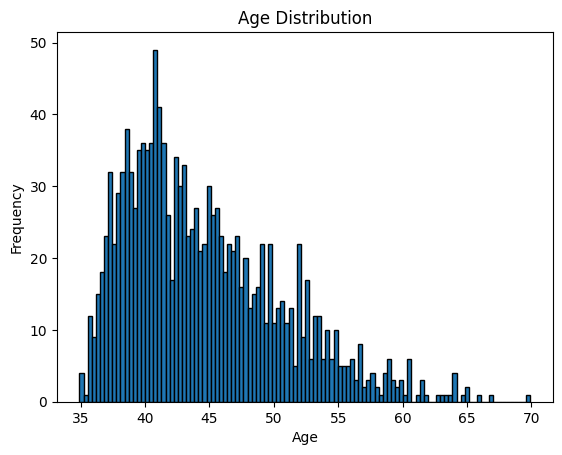

In [ ]:
# Plotting the ensemble age predictions distribution
plt.hist(y_pred_ensemble, bins=110, edgecolor='black')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Age Distribution')
plt.show()

**Submission file creation**

In [ ]:
import pandas as pd

# Creating a temporary DataFrame
df_out = pd.DataFrame({
    "ID": df_judge["ID"],
    "age": y_pred_ensemble.flatten()
})

# Saving the DF to CSV
df_out.to_csv("submission.csv", index=False)
